# Atera FFPE human BRCA supplementary figures

This notebook is the renderer for the Atera ANKRD30A figures. It loads caches generated by `workflow.py`, contains the figure-specific panel code, assembles the two PDF figures, and saves them under `figures/atera_ffpe_human_brca/`. Top-20 SVP PNGs are rendered by the standalone top-20 script or the workflow default stage.

In [1]:
# Shared setup, constants, data loaders, and small helpers used by both PDFs.
from pathlib import Path
import sys

# Make notebook execution robust from either the repo root or this script folder.
PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "scripts" / "atera_ffpe_human_brca").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import gzip
import os
import re
from pathlib import Path
from typing import Any

# Keep imports/rendering deterministic in batch and notebook execution.
os.environ.setdefault("NUMBA_DISABLE_JIT", "1")
os.environ.setdefault("MPLBACKEND", "Agg")
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/quadsv_mplconfig")
os.environ.setdefault("XDG_CACHE_HOME", "/private/tmp/quadsv_cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
Path(os.environ["XDG_CACHE_HOME"]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from scipy import stats

from scripts.atera_ffpe_human_brca.config import (
    ANKRD30A_PROBE_MAPPINGS_CSV,
    ANKRD30A_REGULATOR_PRIORITY_CSV,
    ANKRD30A_TRANSCRIPT_ANNOTATIONS_CSV,
    ANKRD30A_TRPS1_PROSEQ_SIGNAL_CSV,
    ANNOTATION_CSV,
    DU_TCGA_FIGURE_PDF,
    FDR_THRESHOLD,
    FINAL_FIGURE_PDF,
    LAYER,
    REMAP_NR_HG38_BED,
    SPATIAL_KEY,
    SV_CSV,
    TABLE_CODEWORD,
    TABLE_GENE,
    TCGA_GDC_CLINICAL_TSV,
    TCGA_METRIC_TABLE_TSV,
)
from scripts.atera_ffpe_human_brca.ankrd30a import (
    PB_TRANSCRIPTS_OF_INTEREST,
    PB_TSS_CORE_BP,
    TARGET_GENE,
    TCGA_ER_POSITIVE_CORRELATION_CSV,
    load_ankrd30a_visualization_cache,
    load_tcga_metrics,
)
from scripts.atera_ffpe_human_brca.utils import load_sdata, remap_target_from_fields, selected_to_dense

MM_PER_INCH = 25.4
MAX_FIGURE_WIDTH_MM = 185.0
FIGURE_WIDTH_IN = min(7.25, MAX_FIGURE_WIDTH_MM / MM_PER_INCH)
MAIN_FIGURE_HEIGHT_IN = 7.65
DU_TCGA_FIGURE_HEIGHT_IN = 8.65
# Dense spatial scatters are rasterized at this dpi; labels/axes stay vector in the PDF.
SPATIAL_RASTER_DPI = 300

plt.rcParams.update(
    {
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "xtick.labelsize": 5,
        "ytick.labelsize": 5,
        "legend.fontsize": 5,
        "legend.title_fontsize": 5.5,
        "figure.titlesize": 7,
        "savefig.dpi": 600,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


GROUP_COL = "cell_group"
GROUP_COLOR_COL = "cell_group_color"
GENCODE_TRANSCRIPT_205 = "ENST00000696674.1"
PANEL_B_PROBES = ("ANKRD30A|6037", "ANKRD30A|50762", "ANKRD30A|45213", "ANKRD30A|7939")
PROBES_OF_INTEREST = {6037, 7939, 45213, 50762}
PB_TSS_HYPOTHESIS_TRANSCRIPTS = PB_TRANSCRIPTS_OF_INTEREST
PB_TSS_WINDOW_BP = 13_000
PB_TSS_REMAP_TFS = ("ESR1", "FOXA1", "AR", "NR3C1", "BRD4", "STAT3", "SMARCA4")
DU_RAW_P_CUTOFF = 0.01
DU_SCORE_CAP = 50.0
PROBE_CLASS_COLORS = {
    "45213+50762": "#D95F02",
    "50762+7939": "#4C78A8",
}
PROBE_CLASS_SHORT_LABELS = {
    "45213+50762": "L",
    "50762+7939": "I",
}
PROBE_CLASS_ORDER = {
    "45213-only": 0,
    "45213+50762": 1,
    "50762-only": 2,
    "50762+7939": 3,
    "7939-only": 4,
    "broad long-compatible": 5,
    "other multi-probe": 6,
    "no-overlap": 7,
}
LUMINAL_ASSOC_COLOR = PROBE_CLASS_COLORS["45213+50762"]
INVASIVE_ASSOC_COLOR = PROBE_CLASS_COLORS["50762+7939"]
DE_NOVO_TF_COLOR = "#6B6B6B"
TSS_PEAK_TF_COLOR = "#7B3294"
CORE_TSS_PEAK_COLOR = "#111111"
OTHER_TSS_PEAK_COLOR = "#9A9A9A"
NS_ASSOC_COLOR = "#D9D9D9"

TRPS1_PROSEQ_FEATURE_STYLES = {
    "PB.3828.84": {"marker": "o", "linestyle": "-", "alpha": 1.0},
    "PB.3828.2": {"marker": "^", "linestyle": "--", "alpha": 0.9},
    "PB.3828.56": {"marker": "o", "linestyle": "-", "alpha": 1.0},
    "PB.3828.107": {"marker": "D", "linestyle": "--", "alpha": 0.9},
    "ANKRD30A_gene_body": {"marker": "s", "linestyle": ":", "alpha": 0.95},
}

TCGA_EVENT_FEATURES = (
    {
        "label": "PB84",
        "class": "45213+50762",
        "kind": "transcript",
        "expr": "ankrd30a_PB_3828_84_counts",
        "usage": "ankrd30a_PB_3828_84_usage",
        "expr_target": "PB.3828.84 transcript counts",
        "usage_target": "PB.3828.84 usage",
    },
    {
        "label": "PB2",
        "class": "45213+50762",
        "kind": "transcript",
        "expr": "ankrd30a_PB_3828_2_counts",
        "usage": "ankrd30a_PB_3828_2_usage",
        "expr_target": "PB.3828.2 transcript counts",
        "usage_target": "PB.3828.2 usage",
    },
    {
        "label": "PB56",
        "class": "50762+7939",
        "kind": "transcript",
        "expr": "ankrd30a_PB_3828_56_counts",
        "usage": "ankrd30a_PB_3828_56_usage",
        "expr_target": "PB.3828.56 transcript counts",
        "usage_target": "PB.3828.56 usage",
    },
    {
        "label": "PB107",
        "class": "50762+7939",
        "kind": "transcript",
        "expr": "ankrd30a_PB_3828_107_counts",
        "usage": "ankrd30a_PB_3828_107_usage",
        "expr_target": "PB.3828.107 transcript counts",
        "usage_target": "PB.3828.107 usage",
    },
    {
        "label": "probe\n45213",
        "class": "45213+50762",
        "kind": "probe",
        "expr": "ankrd30a_probe_45213_counts",
        "usage": "ankrd30a_probe_45213_usage",
        "expr_target": "probe 45213 region counts",
        "usage_target": "probe 45213 usage",
    },
    {
        "label": "probe\n50762",
        "class": "broad",
        "kind": "probe",
        "expr": "ankrd30a_probe_50762_counts",
        "usage": "ankrd30a_probe_50762_usage",
        "expr_target": "probe 50762 region counts",
        "usage_target": "probe 50762 usage",
    },
    {
        "label": "probe\n7939",
        "class": "50762+7939",
        "kind": "probe",
        "expr": "ankrd30a_probe_7939_counts",
        "usage": "ankrd30a_probe_7939_usage",
        "expr_target": "probe 7939 region counts",
        "usage_target": "probe 7939 usage",
    },
    {
        "label": "probe\n6037",
        "class": "broad",
        "kind": "probe",
        "expr": "ankrd30a_probe_6037_counts",
        "usage": "ankrd30a_probe_6037_usage",
        "expr_target": "probe 6037 region counts",
        "usage_target": "probe 6037 usage",
    },
)


Load source data precomputed by `workflow.py`.

In [2]:
# Required workflow caches. These checks prevent hidden fallbacks to stale ad hoc files.
WORKFLOW_CACHE_PATHS = (
    SV_CSV,
    ANKRD30A_TRANSCRIPT_ANNOTATIONS_CSV,
    ANKRD30A_PROBE_MAPPINGS_CSV,
    ANKRD30A_REGULATOR_PRIORITY_CSV,
    TCGA_METRIC_TABLE_TSV,
    TCGA_ER_POSITIVE_CORRELATION_CSV,
    REMAP_NR_HG38_BED,
    TCGA_GDC_CLINICAL_TSV,
    ANKRD30A_TRPS1_PROSEQ_SIGNAL_CSV,
)

def load_annotations(cell_ids: pd.Index) -> pd.DataFrame:
    ann = pd.read_csv(ANNOTATION_CSV, keep_default_na=False)
    ann = ann.rename(columns={"group": GROUP_COL, "color": GROUP_COLOR_COL})
    ann["cell_id"] = ann["cell_id"].astype(str)
    ann[GROUP_COLOR_COL] = ann[GROUP_COLOR_COL].replace("", np.nan).fillna("#BDBDBD")
    ann = ann.drop_duplicates("cell_id").set_index("cell_id")

    out = pd.DataFrame(index=cell_ids.astype(str))
    out[GROUP_COL] = out.index.map(ann[GROUP_COL])
    out[GROUP_COLOR_COL] = out.index.map(ann[GROUP_COLOR_COL])
    missing = int(out[GROUP_COL].isna().sum())
    if missing:
        raise ValueError(f"{missing:,} cells are missing cell-state annotations")
    return out

# Main figure loader caches.
_SV_CACHE = None
_MAIN_SPATIAL_CACHE = None
_ANKRD30A_VISUALIZATION_CACHE = None
_PANEL_C_SOURCE_CACHE = None

def load_sv_results() -> pd.DataFrame:
    """Load only the segmented SV columns needed by the summary panel."""
    global _SV_CACHE
    if _SV_CACHE is None:
        require_workflow_cache(SV_CSV)
        usecols = {"gene", "pvalue", "pvalue_adj", "statistic"}
        svp = pd.read_csv(SV_CSV, usecols=lambda col: col in usecols).sort_values(
            ["pvalue_adj", "statistic"], ascending=[True, False]
        )
        svp["svp_rank"] = np.arange(1, svp.shape[0] + 1)
        _SV_CACHE = svp
    return _SV_CACHE


def load_main_spatial_data() -> dict[str, object]:
    """Precompute the minimal codeword spatial arrays used by the main figure."""
    global _MAIN_SPATIAL_CACHE
    if _MAIN_SPATIAL_CACHE is None:
        require_workflow_caches()
        sdata = load_sdata()
        adata = sdata.tables[TABLE_CODEWORD]
        coords = np.asarray(adata.obsm[SPATIAL_KEY])
        annotations = load_annotations(pd.Index(adata.obs_names).astype(str))
        features = [feature for feature in PANEL_B_PROBES if feature in set(adata.var_names.astype(str))]
        missing = [feature for feature in PANEL_B_PROBES if feature not in features]
        if missing:
            raise ValueError(f"Missing requested ANKRD30A codeword features: {missing}")
        counts = selected_to_dense(adata[:, features].layers[LAYER]).astype(np.float32, copy=False)
        _MAIN_SPATIAL_CACHE = {
            "coords": coords,
            "annotations": annotations,
            "probe_features": features,
            "probe_log_counts": np.log1p(counts),
        }
    return _MAIN_SPATIAL_CACHE

def require_columns(frame: pd.DataFrame, columns: set[str] | list[str] | tuple[str, ...], label: str) -> None:
    """Fail fast when a workflow cache is missing columns required by a panel."""
    missing = [col for col in columns if col not in frame.columns]
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}")


def load_ankrd30a_visualization_tables() -> dict[str, pd.DataFrame]:
    """Load and validate the three plain-CSV ANKRD30A figure cache tables."""
    global _ANKRD30A_VISUALIZATION_CACHE
    if _ANKRD30A_VISUALIZATION_CACHE is None:
        for path in (ANKRD30A_TRANSCRIPT_ANNOTATIONS_CSV, ANKRD30A_PROBE_MAPPINGS_CSV, ANKRD30A_REGULATOR_PRIORITY_CSV):
            require_workflow_cache(path)
        cache = load_ankrd30a_visualization_cache()
        required_tables = {
            "transcript_annotations": {
                "annotation_source",
                "feature",
                "transcript_id",
                "chrom",
                "start_0based",
                "end_0based",
                "start_1based",
                "end_1based",
                "strand",
                "tss_1based",
                "ORF_length",
                "FL_counts",
                "FL_samples",
                "er_positive_fl_counts",
                "er_positive_fl_samples",
                "compatible_codewords",
                "compatible_probe_oligos",
                "probe_compatibility_class",
                "probe_class_order",
            },
            "probe_mappings": {
                "mapping_row_id",
                "mapping_status",
                "segment_index",
                "codeword",
                "probe_oligo_label",
                "chrom",
                "start_0based",
                "end_0based",
                "approx_mismatches",
                "approx_tie_index",
            },
            "regulator_priority": {
                "regulator",
                "regulator_class",
                "pvalue",
                "pvalue_adj",
                "ankrd30a_du_rank",
                "has_pb_tss_remap_peak",
                "remap_pb_tss_peak_count",
            },
        }
        missing_tables = [name for name in required_tables if name not in cache]
        if missing_tables:
            raise KeyError(f"ANKRD30A visualization cache is missing tables: {missing_tables}")
        for name, columns in required_tables.items():
            table = cache[name]
            if not isinstance(table, pd.DataFrame):
                raise TypeError(f"ANKRD30A visualization cache `{name}` is not a DataFrame")
            require_columns(table, columns, f"ANKRD30A visualization cache `{name}`")
        _ANKRD30A_VISUALIZATION_CACHE = cache
    return _ANKRD30A_VISUALIZATION_CACHE


def load_ankrd30a_regulator_priority_cached() -> pd.DataFrame:
    """Return the workflow-computed ANKRD30A DU priority table."""
    return load_ankrd30a_visualization_tables()["regulator_priority"].copy()


def _compatibility_summary(compat: pd.DataFrame) -> pd.DataFrame:
    """Summarize compatibility classes from transcript-level annotation rows."""
    if compat.empty:
        return pd.DataFrame(columns=["annotation_source", "probe_compatibility_class", "n_transcripts", "compatible_codewords", "probe_class_order"])
    summary = (
        compat.groupby(["annotation_source", "probe_compatibility_class"], dropna=False)
        .agg(
            n_transcripts=("transcript_id", "nunique"),
            compatible_codewords=("compatible_codewords", lambda values: "|".join(sorted({str(value) for value in values if pd.notna(value)}))),
            probe_class_order=("probe_class_order", "min"),
        )
        .reset_index()
    )
    summary["probe_class_order"] = pd.to_numeric(summary["probe_class_order"], errors="coerce").fillna(99).astype(int)
    return summary.sort_values(["annotation_source", "probe_class_order"]).reset_index(drop=True)


def _load_panel_c_sources() -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
]:
    """Load transcript/probe tables once from the plain-CSV ANKRD30A cache."""
    global _PANEL_C_SOURCE_CACHE
    if _PANEL_C_SOURCE_CACHE is None:
        cache = load_ankrd30a_visualization_tables()
        annotations = cache["transcript_annotations"].copy()
        features = annotations[annotations["annotation_source"].astype(str).eq("GENCODE v49")].copy()
        transcripts = features[features["feature"].astype(str).eq("transcript")].copy()
        pacbio_features = annotations[annotations["annotation_source"].astype(str).eq("PacBio QC pass")].copy()
        pacbio_tx = pacbio_features[pacbio_features["feature"].astype(str).eq("transcript")].copy()
        compat = annotations[annotations["feature"].astype(str).eq("transcript")].copy()
        compat_summary = _compatibility_summary(compat)
        _PANEL_C_SOURCE_CACHE = (
            cache["probe_mappings"].copy(),
            transcripts,
            features,
            pacbio_tx,
            pacbio_features,
            compat,
            compat_summary,
        )
    return _PANEL_C_SOURCE_CACHE


def _class_label(class_name: object) -> str:
    text = str(class_name)
    return {
        "45213-only": "45213-only",
        "45213+50762": "45213+50762",
        "50762-only": "50762-only",
        "50762+7939": "50762+7939",
        "7939-only": "7939-only",
        "broad long-compatible": "broad long",
        "no-overlap": "no probe",
    }.get(text, text)

def require_workflow_cache(path: Path) -> Path:
    """Return a cache path or fail with the workflow command that creates it."""
    if not path.exists():
        raise FileNotFoundError(
            f"Missing workflow cache: {path}. Run `python scripts/atera_ffpe_human_brca/workflow.py --n-jobs 8`."
        )
    return path


def require_workflow_caches() -> None:
    """Validate all cache files consumed by the two figure renderers."""
    for path in WORKFLOW_CACHE_PATHS:
        require_workflow_cache(path)



# DU/TCGA figure loader caches.  These entrypoints live in setup so each
# panel cell can focus on panel-specific derivations and rendering.
_TCGA_METRICS_CACHE = None
_TCGA_CORRELATION_CACHE = None
_TCGA_SURVIVAL_CLINICAL_CACHE = None
_TSS_BINDING_INPUTS_CACHE = None
_TF_PRIORITY_INPUTS_CACHE = None
_TRPS1_PROSEQ_CACHE = None


def load_tcga_metrics_cached() -> pd.DataFrame:
    """Load and trim TCGA metric columns used by count, ratio, and survival panels."""
    global _TCGA_METRICS_CACHE
    if _TCGA_METRICS_CACHE is None:
        metrics = load_tcga_metrics()
        needed = {"case_submitter_id", "sample15", "er_status_clean", "ankrd30a_gene_region_counts_total"}
        for spec in TCGA_EVENT_FEATURES:
            needed.update(str(spec[key]) for key in ("expr", "usage") if key in spec)
        needed.update({"ankrd30a_pb84_2_usage_fraction", "ankrd30a_probe_45213_usage_fraction"})
        require_columns(metrics, needed, "TCGA ANKRD30A metric cache")
        _TCGA_METRICS_CACHE = metrics[list(needed)].copy()
    return _TCGA_METRICS_CACHE


def load_tcga_correlations_cached() -> pd.DataFrame:
    """Load only the ER+ TCGA regulator-correlation columns used by the heatmap."""
    global _TCGA_CORRELATION_CACHE
    if _TCGA_CORRELATION_CACHE is None:
        corr = pd.read_csv(require_workflow_cache(TCGA_ER_POSITIVE_CORRELATION_CSV))
        keep = ["regulator", "target_label", "spearman_rho", "pvalue"]
        require_columns(corr, keep, "TCGA ER+ regulator-correlation cache")
        _TCGA_CORRELATION_CACHE = corr[keep].copy()
    return _TCGA_CORRELATION_CACHE


def load_tcga_survival_clinical_cached() -> pd.DataFrame:
    """Load TCGA survival fields once for preview and combined figure cells."""
    global _TCGA_SURVIVAL_CLINICAL_CACHE
    if _TCGA_SURVIVAL_CLINICAL_CACHE is None:
        clinical = pd.read_csv(require_workflow_cache(TCGA_GDC_CLINICAL_TSV), sep="	")
        required = ["case_submitter_id", "os_event", "os_days"]
        missing = [col for col in required if col not in clinical]
        if missing:
            raise ValueError(f"TCGA clinical cache is missing survival columns: {missing}")
        keep = [col for col in ["case_submitter_id", "vital_status", "os_event", "os_days"] if col in clinical]
        _TCGA_SURVIVAL_CLINICAL_CACHE = clinical[keep].drop_duplicates("case_submitter_id")
    return _TCGA_SURVIVAL_CLINICAL_CACHE


def load_trps1_proseq_cached() -> pd.DataFrame:
    """Load the workflow-computed T47D TRPS1 PRO-seq ANKRD30A signal cache."""
    global _TRPS1_PROSEQ_CACHE
    if _TRPS1_PROSEQ_CACHE is None:
        signal = pd.read_csv(require_workflow_cache(ANKRD30A_TRPS1_PROSEQ_SIGNAL_CSV))
        keep = [
            "feature_id",
            "feature_type",
            "plot_order",
            "display_label",
            "event_class",
            "timepoint",
            "timepoint_order",
            "combined_abs_sum",
            "log2fc_combined_abs_sum_vs_0h",
        ]
        require_columns(signal, keep, "TRPS1 PRO-seq signal cache")
        _TRPS1_PROSEQ_CACHE = signal[keep].copy()
    return _TRPS1_PROSEQ_CACHE.copy()


def load_tss_binding_inputs() -> dict[str, pd.DataFrame]:
    """Return cached row-1 TSS hypothesis and ReMap binding tables."""
    global _TSS_BINDING_INPUTS_CACHE
    if _TSS_BINDING_INPUTS_CACHE is None:
        _overlaps, _transcripts, _features, pacbio_tx, _pacbio_features, compat, _summary = _load_panel_c_sources()
        hypothesis_tss = _pb_tss_hypothesis_table(pacbio_tx, compat)
        remap_pb = _load_pb_tss_remap_peaks(hypothesis_tss)
        binding_by_class = _remap_binding_by_tss_class(remap_pb)
        _TSS_BINDING_INPUTS_CACHE = {
            "hypothesis_tss": hypothesis_tss,
            "remap_pb": remap_pb,
            "binding_by_class": binding_by_class,
        }
    return _TSS_BINDING_INPUTS_CACHE


def load_tf_priority_inputs() -> dict[str, object]:
    """Return cached row-2 TF priority and Atera expression inputs."""
    global _TF_PRIORITY_INPUTS_CACHE
    if _TF_PRIORITY_INPUTS_CACHE is None:
        tss_inputs = load_tss_binding_inputs()
        priority = _du_tcga_focus_priority(load_ankrd30a_regulator_priority_cached(), tss_inputs["binding_by_class"], top_n_each=5)
        focus_tfs = priority["regulator"].astype(str).tolist() if not priority.empty else []
        violin_tfs = _tf_expression_panel_tfs(priority)
        violin_data, tf_logfc, violin_counts = _prepare_atera_tf_expression(
            list(dict.fromkeys([*focus_tfs, *violin_tfs]))
        )
        _TF_PRIORITY_INPUTS_CACHE = {
            "focus_priority": priority,
            "focus_tfs": focus_tfs,
            "violin_tfs": violin_tfs,
            "violin_data": violin_data,
            "violin_counts": violin_counts,
            "tf_logfc": tf_logfc,
        }
    return _TF_PRIORITY_INPUTS_CACHE


## Atera SPLISOSM run summary and ANKRD30A spatial plots

In the first figure, we show the overall SPLISOSM spatial variable probe usage results and highlight an ANKRD30A probe switching events between luminal DCIS and invasive breast cancer tumor cells.

### Row 1: SPLISOSM summary of spatial variable probe usage

In [3]:
# Spatial plots of annotated Atera cell states
def plot_cell_states(
    ax: Any,
    coords: np.ndarray,
    annotations: pd.DataFrame,
    *,
    title: str,
    max_groups: int = 12,
) -> None:
    ax.set_axis_off()
    ax.set_aspect("equal")
    order = annotations[GROUP_COL].value_counts().head(max_groups).index.tolist()
    palette = (
        annotations.drop_duplicates(GROUP_COL)
        .set_index(GROUP_COL)[GROUP_COLOR_COL]
        .to_dict()
    )
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c="#E5E5E5",
        s=0.08,
        linewidths=0,
        alpha=0.25,
        rasterized=True,
    )
    for group in order:
        mask = annotations[GROUP_COL].astype(str).eq(group).to_numpy()
        ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            c=palette.get(group, "#777777"),
            s=0.18,
            linewidths=0,
            alpha=0.9,
            label=group,
            rasterized=True,
        )
    handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=palette.get(group, "#777777"),
            markeredgecolor="none",
            markersize=3.2,
            label=group,
        )
        for group in order
    ]
    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0.0, -0.16),
        frameon=False,
        fontsize=4.8,
        handlelength=0.75,
        handletextpad=0.20,
        borderaxespad=0.0,
        columnspacing=1.05,
        labelspacing=0.18,
        ncol=3,
    )

# P-value distribution of HSIC-IR test
def plot_hsic_ir_pvalue_distribution(ax: Any, svp: pd.DataFrame) -> pd.DataFrame:
    plot_df = svp.copy()
    p = pd.to_numeric(plot_df["pvalue"], errors="coerce").to_numpy(dtype=float)
    positive = p[np.isfinite(p) & (p > 0)]
    floor = min(float(np.nanmin(positive)) / 10.0, 1e-300) if positive.size else 1e-300
    floor = max(floor, 1e-320)
    plot_df["pvalue_for_plot"] = np.where(np.isfinite(p) & (p > 0), p, floor)
    plot_df["pvalue_underflow_zero"] = np.isfinite(p) & (p <= 0)
    plot_df["neglog10_hsic_ir_pvalue"] = -np.log10(plot_df["pvalue_for_plot"])
    xmax = float(np.nanpercentile(plot_df["neglog10_hsic_ir_pvalue"], 99.8))
    xmax = max(20.0, min(max(xmax, plot_df["neglog10_hsic_ir_pvalue"].max()), 320.0))
    bins = np.linspace(0, xmax, 64)
    ax.hist(
        np.clip(plot_df["neglog10_hsic_ir_pvalue"], 0, xmax),
        bins=bins,
        color="#C9CDD3",
        edgecolor="white",
        linewidth=0.45,
        log=True,
    )

    top = plot_df.head(8).copy()
    ankrd = plot_df[plot_df["gene"].astype(str).eq(TARGET_GENE)].head(1)
    top = pd.concat([top, ankrd], ignore_index=True).drop_duplicates("gene")
    top = top.sort_values(["svp_rank", "statistic"], ascending=[True, False])
    top["x_for_plot"] = np.clip(top["neglog10_hsic_ir_pvalue"], 0, xmax)

    y_positions = np.geomspace(
        max(ax.get_ylim()[1] / 2.3, 1.0),
        max(ax.get_ylim()[1] / 80, 1.0),
        top.shape[0],
    )
    colors = np.where(top["gene"].astype(str).eq(TARGET_GENE), "#C2185B", "#1B5E9E")
    for (_, row), y, color in zip(top.iterrows(), y_positions, colors, strict=False):
        x = float(row["x_for_plot"])
        ax.scatter([x], [y], s=28, color=color, edgecolor="white", linewidth=0.5, zorder=5)
        label = str(row["gene"])
        if bool(row["pvalue_underflow_zero"]):
            label += " (p<floor)"
        ax.annotate(
            label,
            xy=(x, y),
            xytext=(-6, 0) if x > xmax * 0.82 else (6, 0),
            textcoords="offset points",
            ha="right" if x > xmax * 0.82 else "left",
            va="center",
            fontsize=5.5,
            color=color,
            arrowprops=dict(
                arrowstyle="-",
                color=color,
                linewidth=0.55,
                shrinkA=0,
                shrinkB=3,
            ),
        )

    ax.set_xlabel("-log10 HSIC-IR p-value")
    ax.set_ylabel("Number of genes")
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.55)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(
        0.52,
        0.38,
        f"{plot_df.shape[0]:,} genes tested\n"
        f"{(plot_df['pvalue_adj'] < FDR_THRESHOLD).sum():,} genes FDR < {FDR_THRESHOLD:g}\n"
        f"{int(plot_df['pvalue_underflow_zero'].sum()):,} p-values underflowed to 0",
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=5.5,
        bbox=dict(facecolor="white", edgecolor="#DDDDDD", boxstyle="round,pad=0.25", alpha=0.92),
    )
    return top.copy()

def plot_panel_a(fig: Any, gs: Any, spatial: dict[str, object], svp: pd.DataFrame) -> None:
    coords = spatial["coords"]
    annotations = spatial["annotations"]
    panel_gs = gs.subgridspec(1, 2, width_ratios=[1.08, 1.0], wspace=0.14)
    ax_state = fig.add_subplot(panel_gs[0, 0])
    ax_hsic = fig.add_subplot(panel_gs[0, 1])
    plot_cell_states(ax_state, coords, annotations, title="Segmented Atera cell states")
    plot_hsic_ir_pvalue_distribution(ax_hsic, svp)

    # The histogram axis is visually taller than the spatial map; trim its top so
    # both row-1 title baselines read as one aligned row.
    hsic_bbox = ax_hsic.get_position(fig)
    ax_hsic.set_position([
        hsic_bbox.x0,
        hsic_bbox.y0,
        hsic_bbox.width,
        hsic_bbox.height * 0.90,
    ])

    # Use figure-level labels so the two row-1 titles share one baseline.
    title_y = max(ax_state.get_position(fig).y1, ax_hsic.get_position(fig).y1) + 0.01
    for ax, title in [
        (ax_state, "Segmented Atera cell states"),
        (ax_hsic, "Segmented SplisosmNP HSIC-IR p-value distribution"),
    ]:
        bbox = ax.get_position(fig)
        fig.text((bbox.x0 + bbox.x1) / 2, title_y, title, ha="center", va="bottom", fontsize=7)

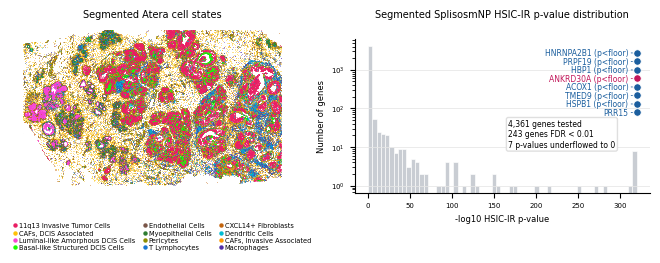

In [4]:
# Preview panel A without writing a PDF.
_svp_preview = load_sv_results()
_spatial_preview = load_main_spatial_data()
_fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 2.55), constrained_layout=False)
_gs = _fig.add_gridspec(1, 1, left=0.055, right=0.962, top=0.90, bottom=0.23)
plot_panel_a(_fig, _gs[0, 0], _spatial_preview, _svp_preview)
plt.show()
plt.close(_fig)

### Row 2: spatial expression of ANKRD30A probes

In [5]:
def _spatial_log_count(ax: Any, coords: np.ndarray, values: np.ndarray, title: str) -> None:
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=6, y=1.02)
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c="#ECECEC",
        s=0.05,
        linewidths=0,
        alpha=0.25,
        rasterized=True,
    )
    valid = np.isfinite(values)
    if not np.any(valid):
        return
    positive = valid & (values > 0)
    draw = positive if positive.any() else valid
    vmax = float(np.nanpercentile(values[draw], 99.5))
    if not np.isfinite(vmax) or vmax <= 0:
        vmax = float(np.nanmax(values[draw])) if draw.any() else 1.0
    image = ax.scatter(
        coords[draw, 0],
        coords[draw, 1],
        c=values[draw],
        s=0.18,
        linewidths=0,
        alpha=0.9,
        cmap="Purples",
        vmin=0.0,
        vmax=vmax,
        rasterized=True,
    )
    cax = ax.inset_axes([1.015, 0.18, 0.032, 0.62])
    cbar = ax.figure.colorbar(image, cax=cax)
    cbar.outline.set_linewidth(0.3)
    cbar.set_ticks([0.0, vmax])
    cbar.set_ticklabels(["0", f"{vmax:.1f}"])
    cbar.ax.yaxis.set_ticks_position("left")
    cbar.ax.tick_params(labelsize=5, length=1.5, width=0.35, pad=1)

def plot_panel_b(fig: Any, gs: Any, spatial: dict[str, object]) -> None:
    coords = spatial["coords"]
    features = spatial["probe_features"]
    log_counts = spatial["probe_log_counts"]
    panel_gs = gs.subgridspec(1, 4, wspace=0.16)
    for i, feature in enumerate(features):
        ax = fig.add_subplot(panel_gs[0, i])
        _spatial_log_count(
            ax,
            coords,
            log_counts[:, i],
            f"{feature}\nlog1p count",
        )

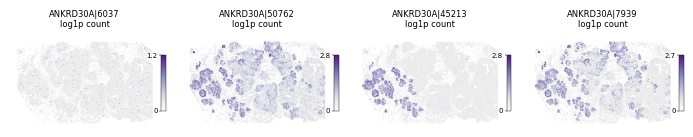

In [6]:
# Preview panel B without writing a PDF.
_spatial_preview = load_main_spatial_data()
_fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 1.25), constrained_layout=False)
_gs = _fig.add_gridspec(1, 1, left=0.04, right=0.96, top=0.82, bottom=0.05)
plot_panel_b(_fig, _gs[0, 0], _spatial_preview)
plt.show()
plt.close(_fig)

### Row 3: ANKRD30A probe-to-transcript mapping

In [7]:
def _select_pacbio_panel_transcripts(transcripts: pd.DataFrame, compat: pd.DataFrame) -> pd.DataFrame:
    """Select the PB transcript rows used for the luminal-vs-invasive TSS model."""
    if transcripts.empty:
        raise ValueError("PacBio transcript annotations are required for panel C")
    work = transcripts.copy()
    required = [
        "transcript_id",
        "start_0based",
        "end_0based",
        "probe_compatibility_class",
        "probe_class_order",
        "FL_counts",
        "FL_samples",
        "er_positive_fl_counts",
        "er_positive_fl_samples",
        "ORF_length",
    ]
    missing = [col for col in required if col not in work.columns]
    if missing:
        pacbio_compat = compat[compat["annotation_source"].astype(str).eq("PacBio QC pass")].copy()
        merge_cols = ["transcript_id", *[col for col in missing if col in pacbio_compat.columns]]
        if len(merge_cols) > 1:
            work = work.merge(pacbio_compat[merge_cols].drop_duplicates("transcript_id"), on="transcript_id", how="left")
    require_columns(work, required, "PacBio transcript annotations")
    for col in ["FL_counts", "FL_samples", "er_positive_fl_counts", "er_positive_fl_samples", "probe_class_order"]:
        work[col] = pd.to_numeric(work[col], errors="coerce")
    candidates = work[work["probe_compatibility_class"].astype(str).isin(PROBE_CLASS_COLORS)].copy()
    missing_classes = sorted(set(PROBE_CLASS_COLORS) - set(candidates["probe_compatibility_class"].astype(str)))
    if missing_classes:
        raise ValueError(f"PacBio transcript cache lacks focused compatibility classes: {missing_classes}")
    selected = (
        candidates.sort_values(
            ["probe_class_order", "er_positive_fl_counts", "er_positive_fl_samples", "FL_counts", "transcript_id"],
            ascending=[True, False, False, False, True],
        )
        .groupby("probe_compatibility_class", group_keys=False)
        .head(2)
    )
    return selected.reset_index(drop=True)


def _transcript_class_map(compat: pd.DataFrame, source: str) -> dict[str, str]:
    """Return transcript-to-probe-class labels for one validated annotation source."""
    require_columns(compat, ["annotation_source", "transcript_id", "probe_compatibility_class"], "transcript compatibility rows")
    sub = compat[compat["annotation_source"].astype(str).eq(source)].copy()
    if sub.empty:
        raise ValueError(f"Transcript compatibility cache lacks source `{source}`")
    return sub.set_index("transcript_id")["probe_compatibility_class"].astype(str).to_dict()


def _probe_class_note(compat_summary: pd.DataFrame) -> str:
    """Return the fixed biological interpretation note after cache validation."""
    require_columns(compat_summary, ["annotation_source", "probe_compatibility_class"], "probe compatibility summary")
    pacbio = compat_summary[compat_summary["annotation_source"].astype(str).eq("PacBio QC pass")]
    if pacbio.empty:
        raise ValueError("Probe compatibility summary lacks PacBio rows")
    return "Highlighted PacBio isoform classes: 45213+50762 (luminal) vs 50762+7939 (invasive)"

def plot_panel_c(fig: Any, gs: Any) -> None:
    (
        overlaps,
        transcripts,
        features,
        pacbio_tx,
        pacbio_features,
        compat,
        compat_summary,
    ) = _load_panel_c_sources()
    ax = fig.add_subplot(gs)
    label_x = -240

    windows = [
        {"start": 37125000, "end": 37126950, "label": "5' exons\n6037 / 50762a"},
        {"start": 37141450, "end": 37142780, "label": "45213"},
        {"start": 37169000, "end": 37193680, "label": "50762b/c\nupstream PB TSSs"},
        {"start": 37216800, "end": 37221890, "label": "7939 region\nlocal PB TSSs"},
        {"start": 37231850, "end": 37233350, "label": "3' end"},
    ]
    gap = 620
    cursor = 0
    for window in windows:
        width = int(window["end"]) - int(window["start"])
        window["mapped_start"] = cursor
        window["mapped_end"] = cursor + width
        cursor += width + gap

    def mapped_coord(coord: float) -> float | None:
        for window in windows:
            if int(window["start"]) <= coord <= int(window["end"]):
                return float(window["mapped_start"]) + coord - int(window["start"])
        return None

    def draw_window_labels(axis: Any) -> None:
        for i, window in enumerate(windows):
            color = "#F7F8FA" if i % 2 == 0 else "#FFFFFF"
            axis.axvspan(window["mapped_start"], window["mapped_end"], color=color, zorder=0)
            if i < len(windows) - 1:
                x = window["mapped_end"] + gap / 2
                axis.text(x, 0.02, "//", ha="center", va="bottom", fontsize=7, color="#777777")

    def draw_line(axis: Any, start: int, end: int, y: float, **kwargs: Any) -> None:
        for window in windows:
            lo = max(start, int(window["start"]))
            hi = min(end, int(window["end"]))
            if hi > lo:
                axis.plot(
                    [
                        window["mapped_start"] + lo - int(window["start"]),
                        window["mapped_start"] + hi - int(window["start"]),
                    ],
                    [y, y],
                    **kwargs,
                )

    def rect_bounds(start: int, end: int, min_width: float) -> list[tuple[float, float]]:
        """Return displayed x-bounds for a genomic interval after window compression."""
        bounds: list[tuple[float, float]] = []
        for window in windows:
            lo = max(start, int(window["start"]))
            hi = min(end, int(window["end"]))
            if hi > lo:
                x = float(window["mapped_start"]) + lo - int(window["start"])
                width = hi - lo
                if width < min_width:
                    x -= (min_width - width) / 2
                    width = min_width
                bounds.append((x, x + width))
        return bounds

    def draw_rect(
        axis: Any,
        start: int,
        end: int,
        y: float,
        height: float,
        min_width: float,
        **kwargs: Any,
    ) -> list[tuple[float, float]]:
        bounds = rect_bounds(start, end, min_width)
        for x0, x1 in bounds:
            axis.add_patch(Rectangle((x0, y - height / 2), x1 - x0, height, **kwargs))
        return bounds

    draw_window_labels(ax)
    tx_order = [
        "ENST00000361713.2",
        "ENST00000374660.7",
        "ENST00000602533.7",
        "ENST00000475522.1",
        GENCODE_TRANSCRIPT_205,
    ]
    missing_ref = [tx for tx in tx_order if tx not in set(transcripts["transcript_id"].astype(str))]
    if missing_ref:
        raise ValueError(f"GENCODE transcript annotations missing expected ANKRD30A rows: {missing_ref}")
    gencode_class = _transcript_class_map(compat, "GENCODE v49")
    pacbio_display = _select_pacbio_panel_transcripts(pacbio_tx, compat)
    pacbio_order = pacbio_display["transcript_id"].astype(str).tolist()
    n_ref = len(tx_order)
    n_pacbio = len(pacbio_order)
    total_rows = n_ref + n_pacbio
    y_map = {tx: total_rows - i for i, tx in enumerate(tx_order)}
    pacbio_y_map = {tx: n_pacbio - i for i, tx in enumerate(pacbio_order)}
    for tx in tx_order:
        txf = features[features["transcript_id"].eq(tx)]
        tx_row = transcripts[transcripts["transcript_id"].eq(tx)].iloc[0]
        y = y_map[tx]
        draw_line(
            ax,
            int(tx_row["start_0based"]),
            int(tx_row["end_0based"]),
            y,
            color="#8A8A8A",
            linewidth=0.7,
            zorder=1,
        )
        for _, exon in txf[txf["feature"].eq("exon")].iterrows():
            draw_rect(
                ax,
                int(exon["start_0based"]),
                int(exon["end_0based"]),
                y,
                0.22,
                62,
                facecolor="#B7D7EA",
                edgecolor="#53788B",
                linewidth=0.65,
                zorder=3,
            )
        for _, cds in txf[txf["feature"].eq("CDS")].iterrows():
            draw_rect(
                ax,
                int(cds["start_0based"]),
                int(cds["end_0based"]),
                y,
                0.11,
                42,
                facecolor="#555555",
                edgecolor="none",
                zorder=4,
            )
        ax.text(
            label_x,
            y,
            f"{tx_row['transcript_name']}\n{_class_label(gencode_class[tx])}",
            ha="right",
            va="center",
            fontsize=5,
            color="#444444",
            fontweight="normal",
        )
    pacbio_exons = pacbio_features[pacbio_features["feature"].astype(str).eq("exon")].copy()
    for _, tx_row in pacbio_display.iterrows():
        tx = str(tx_row["transcript_id"])
        txf = pacbio_exons[pacbio_exons["transcript_id"].astype(str).eq(tx)]
        y = pacbio_y_map[tx]
        probe_class = _class_label(tx_row["probe_compatibility_class"])
        highlight_color = PROBE_CLASS_COLORS.get(probe_class)
        row_color = highlight_color or "#B87333"
        is_highlight = highlight_color is not None
        if is_highlight:
            ax.axhspan(y - 0.36, y + 0.36, color=row_color, alpha=0.08, zorder=0.2)
        draw_line(
            ax,
            int(tx_row["start_0based"]),
            int(tx_row["end_0based"]),
            y,
            color=row_color,
            linewidth=1.0 if is_highlight else 0.65,
            zorder=1,
        )
        for _, exon in txf.iterrows():
            draw_rect(
                ax,
                int(exon["start_0based"]),
                int(exon["end_0based"]),
                y,
                0.23 if is_highlight else 0.2,
                56,
                facecolor="#FAD7A0",
                edgecolor=row_color,
                linewidth=0.95 if is_highlight else 0.6,
                zorder=3,
            )
        fl = pd.to_numeric(tx_row["er_positive_fl_counts"], errors="coerce")
        samples = pd.to_numeric(tx_row["er_positive_fl_samples"], errors="coerce")
        support = "ER+ FL=NA"
        if np.isfinite(fl):
            support = f"ER+ FL={int(fl)}"
        if np.isfinite(samples):
            support += f"; n={int(samples)}"
        orf = pd.to_numeric(tx_row["ORF_length"], errors="coerce")
        orf_label = f"({int(orf)} aa)" if np.isfinite(orf) else "(NA)"
        ax.text(
            label_x,
            y,
            f"{tx} {orf_label}\n{probe_class}\n{support}",
            ha="right",
            va="center",
            fontsize=5,
            linespacing=1,
            color=row_color,
            fontweight="bold" if is_highlight else "normal",
        )

    mapped = overlaps[overlaps["mapping_status"].astype(str).str.startswith("mapped_")].copy()
    probe_colors = {
        45213: LUMINAL_ASSOC_COLOR,
        7939: INVASIVE_ASSOC_COLOR,
        6037: "#7570B3",
        50762: "#666666",
    }
    probe_label_offsets = {
        ("6037", 1): (-130, total_rows + 1.18),
        ("50762a", 1): (145, total_rows + 1.46),
        ("45213", 1): (0, total_rows + 1.38),
        ("7939", 1): (0, total_rows + 1.38),
        ("50762b", 1): (-210, total_rows + 1.42),
        ("50762c", 1): (210, total_rows + 1.15),
        ("50762b", 2): (-210, total_rows + 1.46),
        ("50762c", 2): (210, total_rows + 1.20),
        ("50762c", 3): (0, total_rows + 1.44),
    }
    require_columns(
        mapped,
        ["mapping_row_id", "segment_index", "chrom", "start_0based", "end_0based", "codeword", "probe_oligo_label", "approx_tie_index", "approx_mismatches"],
        "ANKRD30A probe mapping cache",
    )
    for _mapping_id, group in mapped.groupby("mapping_row_id", sort=False):
        row = group.iloc[0]
        codeword = int(row["codeword"])
        mismatch_value = pd.to_numeric(row["approx_mismatches"], errors="coerce")
        is_approx = bool(np.isfinite(mismatch_value) and mismatch_value > 0)
        y = total_rows + 0.66 + (codeword % 2) * 0.16
        if is_approx:
            y += 0.26
        segment_table = group.sort_values("segment_index")
        segments = [(str(seg["chrom"]), int(seg["start_0based"]), int(seg["end_0based"])) for _, seg in segment_table.iterrows()]
        visible_bounds: list[tuple[float, float]] = []
        for _chrom, start0, end0 in segments:
            visible_bounds.extend(
                draw_rect(
                    ax,
                    int(start0),
                    int(end0),
                    y,
                    0.14,
                    95,
                    facecolor=probe_colors.get(codeword, "#999999"),
                    edgecolor="#222222",
                    linewidth=0.45,
                    hatch="///" if is_approx else None,
                    alpha=0.85 if is_approx else 1.0,
                    zorder=6,
                )
            )
        visible_bounds = sorted(visible_bounds)
        if len(visible_bounds) > 1:
            for (_left0, right0), (left1, _right1) in zip(visible_bounds[:-1], visible_bounds[1:]):
                ax.plot(
                    [right0, left1],
                    [y, y],
                    color=probe_colors.get(codeword, "#999999"),
                    linewidth=0.45,
                    linestyle=(0, (1.2, 1.2)),
                    alpha=0.75,
                    zorder=5.5,
                )
        x = None
        if visible_bounds:
            x = (min(left for left, _right in visible_bounds) + max(right for _left, right in visible_bounds)) / 2
        elif segments:
            x = mapped_coord(float(segments[0][1]))
        else:
            x = mapped_coord(float(row["start_0based"]))
        if x is not None and codeword in PROBES_OF_INTEREST:
            label = str(row["probe_oligo_label"])
            label_text = label
            tie_idx_int = int(pd.to_numeric(row["approx_tie_index"], errors="raise"))
            xoff, label_y = probe_label_offsets.get((label, tie_idx_int), (0, total_rows + 1.35))
            ax.annotate(
                label_text,
                xy=(x, y + 0.06),
                xytext=(x + xoff, label_y),
                textcoords="data",
                ha="center",
                va="bottom",
                fontsize=5,
                color=probe_colors[codeword],
                arrowprops=dict(arrowstyle="-", linewidth=0.55, color=probe_colors[codeword]),
            )
    ax.text(label_x, total_rows + 0.76, "Atera probes", ha="right", va="center", fontsize=5.2, fontweight="bold")
    ax.text(
        windows[-1]["mapped_end"],
        total_rows + 2.03,
        _probe_class_note(compat_summary),
        ha="right",
        va="center",
        fontsize=5,
        color="#555555",
    )
    ax.set_ylim(0.05, total_rows + 2.3)
    ax.set_xlim(-4500, windows[-1]["mapped_end"] + 130)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.spines[["top", "left", "right", "bottom"]].set_visible(False)


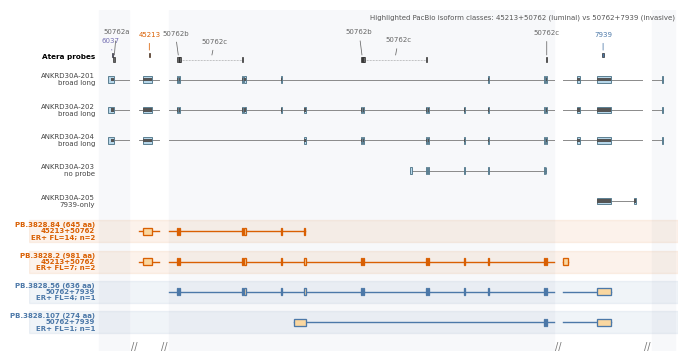

In [8]:
# Preview panel C without writing a PDF.
_fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 3.75), constrained_layout=False)
_gs = _fig.add_gridspec(1, 1, left=0.09, right=0.985, top=0.95, bottom=0.04)
plot_panel_c(_fig, _gs[0, 0])
plt.show()
plt.close(_fig)

### Combined figure

Finally, merge the three panels into a single figure and save as PDF.

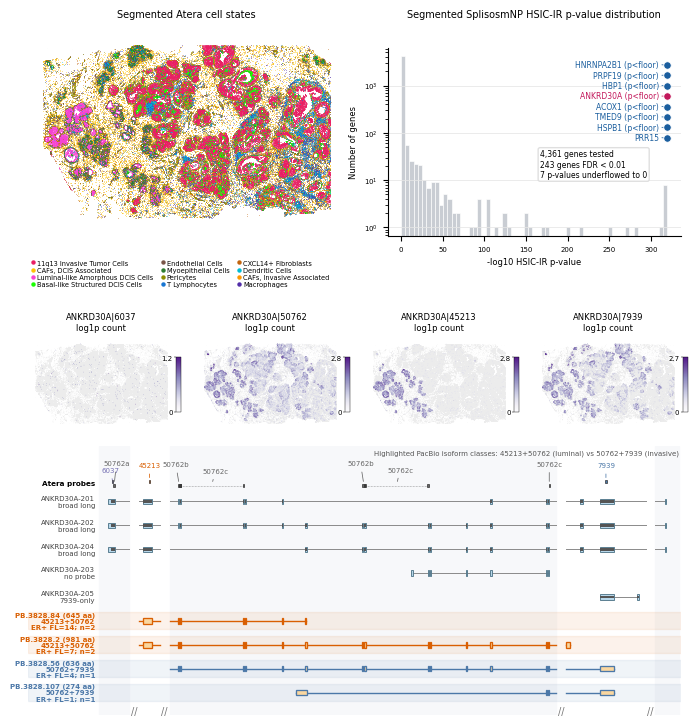

PosixPath('/Users/jysumac/Projects/quadsv-paper/figures/atera_ffpe_human_brca/atera_ankrd30a.pdf')

In [9]:
# Combined main figure: show in notebook and save the PDF.
_svp = load_sv_results()
_spatial = load_main_spatial_data()
FINAL_FIGURE_PDF.parent.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(FIGURE_WIDTH_IN, MAIN_FIGURE_HEIGHT_IN), constrained_layout=False)
outer = fig.add_gridspec(
    2,
    1,
    height_ratios=[2.5, 4.5],
    left=0.05,
    right=0.95,
    top=0.95,
    bottom=0.05,
    hspace=0.35,
)

# Top row: tissue annotation and ranked segmented SV evidence.
plot_panel_a(fig, outer[0, 0], _spatial, _svp)

# Bottom block: selected Atera probe maps followed by PB/reference structures.
lower = outer[1, 0].subgridspec(2, 1, height_ratios=[1.12, 3.35], hspace=0.1)
plot_panel_b(fig, lower[0, 0], _spatial)
plot_panel_c(fig, lower[1, 0])

fig.savefig(FINAL_FIGURE_PDF, dpi=SPATIAL_RASTER_DPI)
plt.show()
plt.close(fig)
FINAL_FIGURE_PDF


## ANKRD30A DU analysis and TCGA validation

In the second figure, we show the potential TF regulators of the ANKRD30A variable probe usage (alternative TSS) and validate our association results using ReMap CHIP-seq data and TCGA breast cancer RNA-seq data.

### Row 1: PB-defined TSS classes and ReMap TF binding

Show the four prioritized PacBio ANKRD30A TSS hypotheses and nearby ReMap TF peaks. This preview cell does not save a PDF.


In [10]:
# Row 1 helpers: PB TSS windows and ReMap TF binding.
def _pb_tss_hypothesis_table(transcripts: pd.DataFrame, compat: pd.DataFrame) -> pd.DataFrame:
    """Return the four PB transcript TSS rows used by the DU/TCGA hypothesis panel."""
    required = [
        "transcript_id",
        "tss_1based",
        "FL_counts",
        "FL_samples",
        "er_positive_fl_counts",
        "er_positive_fl_samples",
        "probe_compatibility_class",
        "compatible_codewords",
        "compatible_probe_oligos",
    ]
    work = transcripts[transcripts["transcript_id"].astype(str).isin(PB_TSS_HYPOTHESIS_TRANSCRIPTS)].copy()
    missing_tx = [tx for tx in PB_TSS_HYPOTHESIS_TRANSCRIPTS if tx not in set(work["transcript_id"].astype(str))]
    if missing_tx:
        raise ValueError(f"PacBio TSS cache missing focused transcripts: {missing_tx}")
    missing_cols = [col for col in required if col not in work]
    if missing_cols:
        pacbio_compat = compat[compat["annotation_source"].astype(str).eq("PacBio QC pass")].copy()
        merge_cols = ["transcript_id", *[col for col in missing_cols if col in pacbio_compat.columns]]
        if len(merge_cols) > 1:
            work = work.merge(pacbio_compat[merge_cols].drop_duplicates("transcript_id"), on="transcript_id", how="left")
    require_columns(work, required, "PB TSS hypothesis transcript cache")
    work["_display_order"] = work["transcript_id"].map({tx: i for i, tx in enumerate(PB_TSS_HYPOTHESIS_TRANSCRIPTS)})
    return work.sort_values("_display_order").reset_index(drop=True)

def _pb_tss_focus_tfs() -> set[str]:
    focus = set(PB_TSS_REMAP_TFS)
    priority = load_ankrd30a_regulator_priority_cached()
    regulator_col = "regulator" if "regulator" in priority else "tf"
    if regulator_col in priority:
        focus.update(priority[regulator_col].dropna().astype(str).head(25))
    return focus

def _load_pb_tss_remap_peaks(tss_table: pd.DataFrame) -> pd.DataFrame:
    if tss_table.empty:
        raise ValueError("PB TSS hypothesis table is empty")
    require_columns(tss_table, ["transcript_id", "probe_compatibility_class", "tss_1based"], "PB TSS hypothesis table")
    require_workflow_cache(REMAP_NR_HG38_BED)

    intervals = []
    for _, row in tss_table.iterrows():
        tss = int(row["tss_1based"])
        intervals.append(
            {
                "transcript_id": str(row["transcript_id"]),
                "probe_compatibility_class": str(row.get("probe_compatibility_class", "")),
                "tss_1based": tss,
                "start": tss - PB_TSS_WINDOW_BP,
                "end": tss + PB_TSS_WINDOW_BP,
            }
        )
    min_start = min(interval["start"] for interval in intervals)
    max_end = max(interval["end"] for interval in intervals)
    focus_tfs = _pb_tss_focus_tfs()
    rows: list[dict[str, object]] = []
    with gzip.open(REMAP_NR_HG38_BED, "rt", encoding="utf-8", errors="replace") as handle:
        for line in handle:
            if not line.startswith("chr10\t"):
                continue
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 4:
                continue
            peak_start = int(fields[1])
            peak_end = int(fields[2])
            if peak_start > max_end:
                break
            if peak_end < min_start:
                continue
            tf = remap_target_from_fields(fields)
            if tf is None or tf not in focus_tfs:
                continue
            for interval in intervals:
                if peak_end < interval["start"] or peak_start > interval["end"]:
                    continue
                tss = int(interval["tss_1based"])
                if peak_start <= tss <= peak_end:
                    distance = 0
                else:
                    distance = min(abs(peak_start - tss), abs(peak_end - tss))
                rows.append(
                    {
                        **interval,
                        "tf": tf,
                        "peak_start_0based": peak_start,
                        "peak_end_0based": peak_end,
                        "peak_name": fields[3],
                        "distance_to_tss_bp": int(distance),
                    }
                )
    out = pd.DataFrame(rows)
    if not out.empty:
        out = out.sort_values(["transcript_id", "tf", "distance_to_tss_bp", "peak_start_0based"])
    return out

def _remap_binding_by_tss_class(remap_pb: pd.DataFrame) -> pd.DataFrame:
    """Count unique ReMap binding sites separately for each PB TSS class."""
    columns = [
        "tf",
        "probe_class",
        "n_peaks",
        "n_core_peaks",
        "min_distance_to_tss_bp",
    ]
    if remap_pb.empty:
        return pd.DataFrame(columns=columns)
    work = remap_pb.copy()
    work["probe_class"] = work["probe_compatibility_class"].map(_class_label)
    work = work[work["probe_class"].isin(PROBE_CLASS_COLORS)].copy()
    if work.empty:
        return pd.DataFrame(columns=columns)
    work["distance_to_tss_bp"] = pd.to_numeric(work["distance_to_tss_bp"], errors="coerce")
    work["is_core_peak"] = work["distance_to_tss_bp"].le(PB_TSS_CORE_BP)
    unique = work.drop_duplicates(
        ["tf", "probe_class", "peak_start_0based", "peak_end_0based", "peak_name"]
    )
    summary = (
        unique.groupby(["tf", "probe_class"], as_index=False)
        .agg(
            n_peaks=("peak_name", "size"),
            n_core_peaks=("is_core_peak", "sum"),
            min_distance_to_tss_bp=("distance_to_tss_bp", "min"),
        )
        .sort_values(["tf", "probe_class"])
    )
    return summary[columns]

def _tf_class_peak_counts(binding_by_class: pd.DataFrame, tf: object) -> dict[str, tuple[int, int]]:
    """Return total/core ReMap peak counts for the two ANKRD30A TSS classes."""
    counts = {class_name: (0, 0) for class_name in PROBE_CLASS_COLORS}
    if binding_by_class.empty:
        return counts
    sub = binding_by_class[binding_by_class["tf"].astype(str).eq(str(tf))]
    for _, row in sub.iterrows():
        class_name = str(row["probe_class"])
        if class_name not in counts:
            continue
        n_peaks = pd.to_numeric(row.get("n_peaks", 0), errors="coerce")
        n_core = pd.to_numeric(row.get("n_core_peaks", 0), errors="coerce")
        counts[class_name] = (
            int(n_peaks) if np.isfinite(n_peaks) else 0,
            int(n_core) if np.isfinite(n_core) else 0,
        )
    return counts

def _tf_binding_summary(binding_by_class: pd.DataFrame) -> pd.DataFrame:
    """Summarize class-specific ReMap support per TF for ranking and labels."""
    columns = ["tf", "n_tss_peaks", "n_core_tss_peaks", "min_distance_to_tss_bp"]
    if binding_by_class.empty:
        return pd.DataFrame(columns=columns)
    work = binding_by_class.copy()
    work["n_peaks"] = pd.to_numeric(work["n_peaks"], errors="coerce").fillna(0)
    work["n_core_peaks"] = pd.to_numeric(work["n_core_peaks"], errors="coerce").fillna(0)
    work["min_distance_to_tss_bp"] = pd.to_numeric(work["min_distance_to_tss_bp"], errors="coerce")
    out = (
        work.groupby("tf", as_index=False)
        .agg(
            n_tss_peaks=("n_peaks", "sum"),
            n_core_tss_peaks=("n_core_peaks", "sum"),
            min_distance_to_tss_bp=("min_distance_to_tss_bp", "min"),
        )
        .sort_values(["n_core_tss_peaks", "n_tss_peaks", "min_distance_to_tss_bp", "tf"], ascending=[False, False, True, True])
    )
    return out[columns]

def _draw_tss_class_count_label(
    ax: Any,
    x: float,
    y: float,
    counts: dict[str, tuple[int, int]],
    *,
    fontsize: float = 5,
    step: float = 58,
) -> None:
    """Draw compact luminal/invasive TSS peak counts with event-consistent colors."""
    x_cursor = x
    for class_name, color in PROBE_CLASS_COLORS.items():
        short = PROBE_CLASS_SHORT_LABELS[class_name]
        n_peaks, n_core = counts[class_name]
        label = f"{short}{n_peaks}"
        if n_core:
            label += f"c{n_core}"
        ax.text(
            x_cursor,
            y,
            label,
            ha="left",
            va="center",
            fontsize=fontsize,
            color=color,
        )
        x_cursor += step

def plot_pb_tss_hypothesis(
    ax_reg: Any,
    hypothesis_tss: pd.DataFrame,
    remap_pb: pd.DataFrame,
    binding_by_class: pd.DataFrame,
) -> list[str]:
    """Draw PB-defined TSS windows from precomputed ReMap overlap tables."""
    prom_gap = 4_500
    prom_cursor = 0
    prom_windows: list[dict[str, object]] = []
    for _, row in hypothesis_tss.iterrows():
        tss_pos = int(row["tss_1based"])
        prom_window = {
            "transcript_id": str(row["transcript_id"]),
            "probe_class": _class_label(row["probe_compatibility_class"]),
            "tss": tss_pos,
            "start": tss_pos - PB_TSS_WINDOW_BP,
            "end": tss_pos + PB_TSS_WINDOW_BP,
            "mapped_start": prom_cursor,
            "mapped_end": prom_cursor + 2 * PB_TSS_WINDOW_BP,
            "fl_counts": float(pd.to_numeric(row["FL_counts"], errors="coerce")),
            "fl_samples": float(pd.to_numeric(row["FL_samples"], errors="coerce")),
            "er_positive_fl_counts": float(pd.to_numeric(row["er_positive_fl_counts"], errors="coerce")),
            "er_positive_fl_samples": float(pd.to_numeric(row["er_positive_fl_samples"], errors="coerce")),
        }
        prom_windows.append(prom_window)
        prom_cursor += 2 * PB_TSS_WINDOW_BP + prom_gap
    if not prom_windows:
        raise ValueError("PB TSS hypothesis table did not produce any plotting windows")

    def prom_coord(coord: float, transcript_id: str | None = None) -> float | None:
        for window in prom_windows:
            if transcript_id is not None and window["transcript_id"] != transcript_id:
                continue
            if int(window["start"]) <= coord <= int(window["end"]):
                return float(window["mapped_start"]) + coord - int(window["start"])
        return None

    def prom_rect(start: int, end: int, y: float, height: float, transcript_id: str | None, **kwargs: Any) -> None:
        for window in prom_windows:
            if transcript_id is not None and window["transcript_id"] != transcript_id:
                continue
            lo = max(start, int(window["start"]))
            hi = min(end, int(window["end"]))
            if hi <= lo:
                continue
            x = float(window["mapped_start"]) + lo - int(window["start"])
            ax_reg.add_patch(Rectangle((x, y - height / 2), max(hi - lo, 18), height, **kwargs))

    for i, window in enumerate(prom_windows):
        ax_reg.axvspan(window["mapped_start"], window["mapped_end"], color="#FBFBFB" if i % 2 == 0 else "#FFFFFF")
        tss_x = prom_coord(float(window["tss"]), str(window["transcript_id"]))
        if tss_x is None:
            continue
        er_fl = window.get("er_positive_fl_counts", np.nan)
        er_samples = window.get("er_positive_fl_samples", np.nan)
        support = "ER+ FL=NA"
        if np.isfinite(er_fl):
            support = f"ER+ FL={int(er_fl)}"
        if np.isfinite(er_samples):
            support += f"; n={int(er_samples)}"
        color = PROBE_CLASS_COLORS.get(str(window["probe_class"]), "#7A4A12")
        ax_reg.axvspan(tss_x - PB_TSS_CORE_BP, tss_x + PB_TSS_CORE_BP, color=color, alpha=0.1)
        ax_reg.axvline(tss_x, color=color, linewidth=1.15)
        tx_short = str(window["transcript_id"]).replace("PB.3828.", "PB")
        ax_reg.text(
            tss_x,
            0.98,
            f"{tx_short} TSS\n{window['probe_class']}\n{support}",
            ha="center",
            va="top",
            fontsize=5,
            color=color,
            fontweight="bold",
            linespacing=0.95,
            bbox={
                "boxstyle": "round,pad=0.12",
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.92,
            },
        )
        if i < len(prom_windows) - 1:
            ax_reg.text(
                float(window["mapped_end"]) + prom_gap / 2,
                0.05,
                "//",
                ha="center",
                va="bottom",
                fontsize=7,
                color="#777777",
            )

    if remap_pb.empty:
        tf_order: list[str] = []
    else:
        peak_summary = (
            remap_pb.groupby("tf", as_index=False)
            .agg(min_distance=("distance_to_tss_bp", "min"), n_peaks=("peak_name", "size"))
            .sort_values(["min_distance", "tf"])
        )
        known = [tf for tf in PB_TSS_REMAP_TFS if tf in set(peak_summary["tf"].astype(str))]
        additional = [tf for tf in peak_summary["tf"].astype(str) if tf not in set(known)]
        tf_order = (known + additional)[:9]
    tf_y = {tf: 0.14 + 0.074 * i for i, tf in enumerate(tf_order)}
    for _, row in remap_pb.iterrows():
        tf = str(row["tf"])
        if tf not in tf_y:
            continue
        is_core = pd.to_numeric(row.get("distance_to_tss_bp", np.nan), errors="coerce") <= PB_TSS_CORE_BP
        prom_rect(
            int(row["peak_start_0based"]),
            int(row["peak_end_0based"]),
            tf_y[tf],
            0.06 if bool(is_core) else 0.04,
            str(row["transcript_id"]),
            facecolor=CORE_TSS_PEAK_COLOR if bool(is_core) else OTHER_TSS_PEAK_COLOR,
            edgecolor="none",
            alpha=0.95 if bool(is_core) else 0.72,
            zorder=4 if bool(is_core) else 3,
        )
    tf_label_x = -12_400
    count_label_x = -8_900
    for tf, y in tf_y.items():
        counts = _tf_class_peak_counts(binding_by_class, tf)
        ax_reg.text(
            tf_label_x,
            y,
            tf,
            ha="right",
            va="center",
            fontsize=5,
            color="#333333",
        )
        _draw_tss_class_count_label(
            ax_reg,
            count_label_x,
            y,
            counts,
            fontsize=5,
            step=4_000,
        )
    tick_positions = []
    tick_labels = []
    for window in prom_windows:
        for coord in [int(window["tss"]) - 10_000, int(window["tss"]), int(window["tss"]) + 10_000]:
            x = prom_coord(float(coord), str(window["transcript_id"]))
            if x is not None:
                tick_positions.append(x)
                tick_labels.append(f"{coord:,}")
    ax_reg.set_xlim(-13_500, prom_windows[-1]["mapped_end"] + 120)
    ax_reg.set_ylim(0.02, 1.05)
    ax_reg.set_yticks([])
    ax_reg.set_xticks(tick_positions)
    ax_reg.set_xticklabels(tick_labels, fontsize=5, rotation=18, ha="right")
    ax_reg.set_xlabel("hg38 chr10 coordinate around focused PacBio ANKRD30A TSSs", labelpad=8)
    ax_reg.set_title(f"PacBio-based TSSs and ReMap TF binding sites (core = peak within {PB_TSS_CORE_BP:,} bp of TSS)", loc="left", fontsize=7, y=1.06, pad=0)
    handles = [
        Line2D([0], [0], color=PROBE_CLASS_COLORS["50762+7939"], linewidth=1.8, label="50762+7939: invasive"),
        Line2D([0], [0], color=PROBE_CLASS_COLORS["45213+50762"], linewidth=1.8, label="45213+50762: luminal"),
    ]
    ax_reg.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(1, 1.2),
        frameon=True,
        fontsize=5,
        handlelength=1.6,
        borderpad=0.25,
        ncol=1,
        columnspacing=1.0,
    )
    ax_reg.spines[["top", "left", "right"]].set_visible(False)
    ax_reg.grid(axis="x", color="#EEEEEE", linewidth=0.55)
    return tf_order, binding_by_class


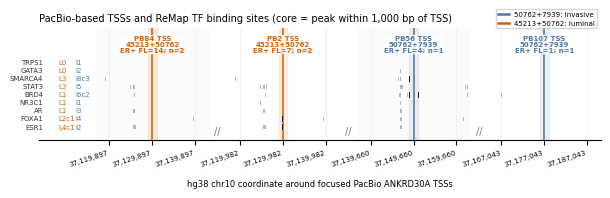

In [11]:
# Preview DU/TCGA panel 1 without writing a PDF.
_tss_inputs = load_tss_binding_inputs()
_fig, _ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 1.45), constrained_layout=False)
plot_pb_tss_hypothesis(
    _ax,
    _tss_inputs["hypothesis_tss"],
    _tss_inputs["remap_pb"],
    _tss_inputs["binding_by_class"],
)
plt.show()
plt.close(_fig)

### Row 2: Atera DU TF prioritization and spatial TF expression

Rank top de novo TFs and top TSS-binding TFs by ANKRD30A DU association, then compare their spatial expression between invasive and luminal/DCIS cells. This preview cell does not save a PDF.


In [12]:
# Row 2 helpers: Atera DU TF priority and spatial TF-expression shift.
def plot_ankrd_tf_priority(
    fig: Any,
    gs: Any,
    priority_sub: pd.DataFrame,
    *,
    binding_by_class: pd.DataFrame | None = None,
) -> list[str]:
    sub = priority_sub.copy()
    ax = fig.add_subplot(gs)
    if sub.empty:
        raise ValueError("ANKRD30A regulator-priority cache has no TF rows for row 2")
    if binding_by_class is None:
        raise ValueError("Row-2 TF priority plotting requires row-1 TSS binding counts")
    require_columns(sub, ["regulator", "plot_group", "is_row1_binding_tf", "pvalue"], "ANKRD30A row-2 TF priority table")

    group_labels = sub["plot_group"].astype(str).tolist()
    y_values: list[float] = []
    group_starts: dict[str, float] = {}
    y_cursor = 0.0
    previous_group: str | None = None
    for group in group_labels:
        if previous_group is not None and group != previous_group:
            y_cursor += 0.75
        group_starts.setdefault(group, y_cursor)
        y_values.append(y_cursor)
        y_cursor += 1.0
        previous_group = group
    y = np.asarray(y_values, dtype=float)
    has_binding = sub["is_row1_binding_tf"].astype(bool)
    raw_p = pd.to_numeric(sub["pvalue"], errors="coerce")
    is_significant = raw_p.lt(DU_RAW_P_CUTOFF)
    finite_positive = raw_p[np.isfinite(raw_p) & raw_p.gt(0)]
    floor = min(float(finite_positive.min()) / 10.0, 1e-50) if not finite_positive.empty else 1e-50
    score = -np.log10(raw_p.where(raw_p.gt(0), floor))
    sub["du_raw_p_score"] = np.clip(score, 0, DU_SCORE_CAP)
    colors = np.where(has_binding, TSS_PEAK_TF_COLOR, DE_NOVO_TF_COLOR)
    colors = np.where(is_significant, colors, "#C7C7C7")
    ax.barh(y, sub["du_raw_p_score"].to_numpy(dtype=float), color=colors, alpha=0.92, height=0.62)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["regulator"].astype(str), fontsize=5.5)
    ax.invert_yaxis()
    ax.set_xlabel("-log10 raw DU p-value")
    ax.set_title("Atera DU TF association", loc="left", y=1.10, pad=0)
    ax.text(
        1.0,
        1.035,
        "L/I=unique TSS peaks",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=5,
        color="#333333",
    )
    for group, start_y in group_starts.items():
        ax.text(
            1.0,
            start_y - 0.55,
            group.replace("Top ", ""),
            ha="left",
            va="center",
            fontsize=5,
            color=TSS_PEAK_TF_COLOR if "binding" in group else DE_NOVO_TF_COLOR,
            fontweight="bold",
            clip_on=False,
        )
    group_boundaries = [y[i] - 0.5 for i in range(1, len(group_labels)) if group_labels[i] != group_labels[i - 1]]
    for boundary in group_boundaries:
        ax.axhline(boundary, color="#CFCFCF", linewidth=0.6, linestyle=":")

    ax.set_xlim(0, DU_SCORE_CAP + 17.0)
    ax.grid(axis="x", color="#E5E5E5", linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    for yi, (_, row) in zip(y, sub.iterrows(), strict=False):
        row_p = pd.to_numeric(row.get("pvalue", np.nan), errors="coerce")
        counts = _tf_class_peak_counts(binding_by_class, row["regulator"])
        has_class_binding = any(n_peaks > 0 for n_peaks, _n_core in counts.values())
        if not has_class_binding and not bool(row.get("has_pb_tss_remap_peak", False)) and np.isfinite(row_p) and row_p < DU_RAW_P_CUTOFF:
            continue
        if has_class_binding:
            _draw_tss_class_count_label(
                ax,
                DU_SCORE_CAP + 1.2,
                yi,
                counts,
                fontsize=5,
                step=6.4,
            )
            if np.isfinite(row_p) and row_p >= DU_RAW_P_CUTOFF:
                ax.text(
                    DU_SCORE_CAP + 13.2,
                    yi,
                    "NS",
                    ha="left",
                    va="center",
                    fontsize=5,
                    color="#666666",
                )
            continue
        if bool(row.get("has_pb_tss_remap_peak", False)):
            peak_count_value = pd.to_numeric(row.get("remap_pb_tss_peak_count", 0), errors="coerce")
            peak_count = int(peak_count_value) if np.isfinite(peak_count_value) else 0
            label = f"{peak_count} peak"
            if peak_count != 1:
                label += "s"
            text_color = "#666666" if np.isfinite(row_p) and row_p >= DU_RAW_P_CUTOFF else TSS_PEAK_TF_COLOR
        elif np.isfinite(row_p) and row_p >= DU_RAW_P_CUTOFF:
            label = f"NS p={row_p:.2g}"
            text_color = "#666666"
        else:
            continue
        ax.text(
            min(float(row["du_raw_p_score"]) + 0.8, DU_SCORE_CAP + 0.8),
            yi,
            label,
            ha="left",
            va="center",
            fontsize=5,
            color=text_color,
        )
    return sub["regulator"].astype(str).tolist()

def _tf_expression_panel_tfs(priority: pd.DataFrame, *, max_tfs: int = 12) -> list[str]:
    """Select a compact mix of top DU TFs and PB-TSS-bound TFs for spatial maps."""
    if priority.empty:
        return []
    selected: list[str] = []
    top_mask = priority["is_top_de_novo_tf"].astype(bool) if "is_top_de_novo_tf" in priority else pd.Series(False, index=priority.index)
    binding_mask = priority["is_row1_binding_tf"].astype(bool) if "is_row1_binding_tf" in priority else pd.Series(False, index=priority.index)
    for mask, limit in [(top_mask, max_tfs // 2), (binding_mask, max_tfs)]:
        for tf in priority.loc[mask, "regulator"].astype(str):
            if tf not in selected:
                selected.append(tf)
            if len(selected) >= limit:
                break
    return selected

def _gene_table_symbol_map(adata_gene: Any) -> dict[str, str]:
    """Map case-insensitive symbols to the exact symbols in the Atera gene table."""
    return {str(name).casefold(): str(name) for name in adata_gene.var_names.astype(str)}

def _sample_for_violin(values: np.ndarray, *, max_points: int = 2500) -> np.ndarray:
    """Return a deterministic subset for compact violin rendering."""
    values = values[np.isfinite(values)]
    if values.size <= max_points:
        return values
    rng = np.random.default_rng(17)
    return values[np.sort(rng.choice(values.size, size=max_points, replace=False))]

def _event_direction_color(direction: float) -> str:
    """Map positive luminal-side or negative invasive-side direction to color."""
    if direction > 0:
        return LUMINAL_ASSOC_COLOR
    if direction < 0:
        return INVASIVE_ASSOC_COLOR
    return "#555555"

_TF_EXPRESSION_CACHE: dict[tuple[str, ...], tuple[pd.DataFrame, dict[str, float], dict[str, int]]] = {}

def _prepare_atera_tf_expression(tfs: list[str]) -> tuple[pd.DataFrame, dict[str, float], dict[str, int]]:
    """Return sampled TF expression values and luminal-minus-invasive logFC."""
    key = tuple(dict.fromkeys(tfs))
    if key in _TF_EXPRESSION_CACHE:
        return _TF_EXPRESSION_CACHE[key]
    if not key:
        raise ValueError("No TFs were selected for Atera expression violin plots")
    sdata = load_sdata()
    if TABLE_GENE not in sdata.tables:
        raise KeyError(f"SpatialData table `{TABLE_GENE}` is required for Atera TF expression plots")
    adata = sdata.tables[TABLE_GENE]
    symbol_map = _gene_table_symbol_map(adata)
    genes = [symbol_map[tf.casefold()] for tf in key if tf.casefold() in symbol_map][:12]
    if not genes:
        raise ValueError("None of the selected TFs are present in the Atera gene table")

    cell_ids = adata.obs["cell_id"].astype(str) if "cell_id" in adata.obs else pd.Index(adata.obs_names).astype(str)
    groups = load_annotations(pd.Index(cell_ids))[GROUP_COL].astype(str)
    masks = {
        "Invasive": groups.str.contains("Invasive Tumor Cells", case=False, regex=False).to_numpy(),
        "Luminal/DCIS": groups.str.contains("Luminal-like", case=False, regex=False).to_numpy(),
    }
    if not masks["Invasive"].any() or not masks["Luminal/DCIS"].any():
        raise ValueError("Atera annotations must contain invasive and luminal/DCIS cell groups")

    values = selected_to_dense(adata[:, genes].X).astype(np.float32, copy=False)
    values = np.log1p(values)
    logfc = {
        gene: float(np.nanmean(values[masks["Luminal/DCIS"], i]) - np.nanmean(values[masks["Invasive"], i]))
        for i, gene in enumerate(genes)
    }
    rows: list[dict[str, object]] = []
    for i, gene in enumerate(genes):
        for label, mask in masks.items():
            for value in _sample_for_violin(values[mask, i]):
                rows.append({"tf": gene, "cell_state": label, "log1p_expression": float(value)})
    table = pd.DataFrame(rows)
    counts = {label: int(mask.sum()) for label, mask in masks.items()}
    _TF_EXPRESSION_CACHE[key] = (table, logfc, counts)
    return table, logfc, counts

def plot_atera_tf_expression_violins(
    fig: Any,
    gs: Any,
    expression: pd.DataFrame,
    tfs: list[str],
    *,
    tf_logfc: dict[str, float] | None = None,
    group_counts: dict[str, int] | None = None,
) -> None:
    """Compare precomputed TF log1p expression in invasive versus luminal cells."""
    ax = fig.add_subplot(gs)
    ax.set_title("Atera TF expression by cell state", loc="left", y=1.10, pad=0)
    if expression.empty or not tfs:
        raise ValueError("Atera TF expression table is empty for the selected regulators")

    genes = [tf for tf in tfs if tf in set(expression["tf"].astype(str))][:12]
    if not genes:
        raise ValueError("Selected TFs are absent from the Atera gene-expression table")

    centers = np.arange(len(genes), dtype=float)
    tf_logfc = tf_logfc or {}
    group_counts = group_counts or {}
    specs = [
        ("Invasive", -0.17, INVASIVE_ASSOC_COLOR),
        ("Luminal/DCIS", 0.17, LUMINAL_ASSOC_COLOR),
    ]
    for i, gene in enumerate(genes):
        gene_values = expression[expression["tf"].astype(str).eq(gene)]
        for label, offset, color in specs:
            violin_values = gene_values.loc[gene_values["cell_state"].eq(label), "log1p_expression"].to_numpy(dtype=float)
            if violin_values.size < 3:
                continue
            parts = ax.violinplot(
                [violin_values],
                positions=[centers[i] + offset],
                widths=0.30,
                showmeans=False,
                showmedians=True,
                showextrema=False,
            )
            for body in parts["bodies"]:
                body.set_facecolor(color)
                body.set_edgecolor("none")
                body.set_alpha(0.48)
                body.set_rasterized(True)
            parts["cmedians"].set_color("#222222")
            parts["cmedians"].set_linewidth(0.55)
    ax.set_xticks(centers)
    ax.set_xticklabels(genes, rotation=45, ha="right", fontsize=5)
    for tick, gene in zip(ax.get_xticklabels(), genes, strict=False):
        direction = float(tf_logfc.get(gene, 0.0))
        tick.set_color(_event_direction_color(direction))
    ax.set_ylabel("log1p expression")
    ax.grid(axis="y", color="#E8E8E8", linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    handles = [
        Line2D([0], [0], marker="s", color="none", markerfacecolor=color, markeredgecolor="none", markersize=5, label=f"{label} n={group_counts.get(label, 0):,}")
        for label, _, color in specs
    ]
    ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=5, handlelength=0.9)

def _du_tcga_focus_priority(priority: pd.DataFrame, binding_by_class: pd.DataFrame, *, top_n_each: int = 5) -> pd.DataFrame:
    """Select top de novo DU TFs and top TSS-binding TFs as two figure groups."""
    if priority.empty:
        raise ValueError("ANKRD30A regulator-priority cache is empty")
    priority = priority.copy()
    priority = priority[priority["regulator_class"].isin(["TF", "RBP+TF"])].copy()
    if priority.empty:
        raise ValueError("ANKRD30A regulator-priority cache has no TF regulators")
    binding = _tf_binding_summary(binding_by_class).rename(columns={"tf": "regulator"})
    priority = priority.merge(binding, on="regulator", how="left")
    for col in ["pvalue", "pvalue_adj", "ankrd30a_du_rank"]:
        priority[col] = pd.to_numeric(priority.get(col, np.nan), errors="coerce")
    for col in ["n_tss_peaks", "n_core_tss_peaks"]:
        priority[col] = pd.to_numeric(priority.get(col, 0), errors="coerce").fillna(0)
    priority["min_distance_to_tss_bp"] = pd.to_numeric(priority.get("min_distance_to_tss_bp", np.nan), errors="coerce")
    priority["has_class_tss_binding"] = priority["n_tss_peaks"].gt(0)

    de_novo = (
        priority[~priority["has_class_tss_binding"]]
        .sort_values(["ankrd30a_du_rank", "regulator"], ascending=[True, True])
        .head(top_n_each)
        .copy()
    )
    de_novo["plot_group"] = "Top de novo DU TFs"

    binding_top = (
        priority[priority["has_class_tss_binding"]]
        .sort_values(
            ["pvalue", "pvalue_adj", "ankrd30a_du_rank", "n_core_tss_peaks", "n_tss_peaks", "min_distance_to_tss_bp", "regulator"],
            ascending=[True, True, True, False, False, True, True],
        )
        .head(top_n_each)
        .copy()
    )
    binding_top["plot_group"] = "Top TSS-binding TFs"

    out = pd.concat([de_novo, binding_top], ignore_index=True)
    out["_plot_order"] = np.arange(out.shape[0])
    out["is_top_de_novo_tf"] = out["plot_group"].eq("Top de novo DU TFs")
    out["is_row1_binding_tf"] = out["plot_group"].eq("Top TSS-binding TFs")
    return out


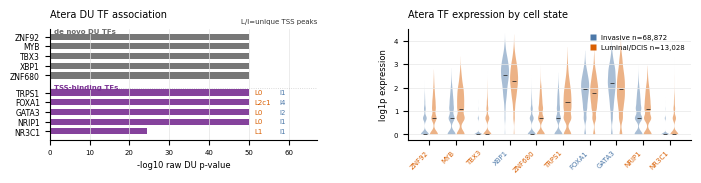

In [13]:
# Preview DU/TCGA panel 2 without writing a PDF.
_tss_inputs = load_tss_binding_inputs()
_tf_inputs = load_tf_priority_inputs()
_fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 1.85), constrained_layout=False)
_gs = _fig.add_gridspec(1, 2, width_ratios=[1.02, 1.08], left=0.08, right=0.965, top=0.86, bottom=0.26, wspace=0.33)
plot_ankrd_tf_priority(
    _fig,
    _gs[0, 0],
    _tf_inputs["focus_priority"],
    binding_by_class=_tss_inputs["binding_by_class"],
)
plot_atera_tf_expression_violins(
    _fig,
    _gs[0, 1],
    _tf_inputs["violin_data"],
    _tf_inputs["violin_tfs"],
    tf_logfc=_tf_inputs["tf_logfc"],
    group_counts=_tf_inputs["violin_counts"],
)
plt.show()
plt.close(_fig)


### Row 3: TCGA ANKRD30A counts and ER+ transcript-ratio survival

Show ER-stratified ANKRD30A transcript/probe counts and the ER+ overall-survival association for the PB84+2 usage ratio. This preview cell does not save a PDF.


In [14]:
# Row 3/4 helpers: TCGA count summaries and ER+ TF correlations.
def _event_metric_specs(metrics: pd.DataFrame) -> list[dict[str, str]]:
    """Return the fixed TCGA event metrics after validating their columns."""
    required = [str(spec["expr"]) for spec in TCGA_EVENT_FEATURES]
    require_columns(metrics, required, "TCGA ANKRD30A event metric cache")
    return [{key: str(value) for key, value in spec.items()} for spec in TCGA_EVENT_FEATURES]

def plot_tcga_count_boxplots(fig: Any, gs: Any, metrics: pd.DataFrame) -> None:
    """Plot TCGA ANKRD30A transcript/probe raw counts by ER status."""
    count_ax = fig.add_subplot(gs)
    if metrics.empty:
        raise ValueError("TCGA ANKRD30A metric cache is empty")
    require_columns(metrics, ["er_status_clean"], "TCGA ANKRD30A metric cache")

    count_metrics = metrics[metrics["er_status_clean"].isin(["positive", "negative"])].copy()
    specs = _event_metric_specs(count_metrics)
    # Add the broad ANKRD30A gene-region total first so event/probe counts are read
    # against the same sample-level gene-count baseline.
    if "ankrd30a_gene_region_counts_total" in count_metrics:
        specs = [
            {
                "label": "gene\ntotal",
                "class": "gene_total",
                "kind": "gene_total",
                "expr": "ankrd30a_gene_region_counts_total",
            },
            *specs,
        ]
    if count_metrics.empty or not specs:
        raise ValueError("TCGA metric cache has no ER-positive/ER-negative samples for count plots")

    status_colors = {"positive": "#C2185B", "negative": "#777777"}

    centers = np.arange(len(specs), dtype=float)
    xticks: list[float] = []
    xticklabels: list[str] = []
    for i, spec in enumerate(specs):
        col = spec["expr"]
        if col not in metrics:
            raise ValueError(f"TCGA metric cache missing count column `{col}`")
        xticks.append(float(i))
        xticklabels.append(spec["label"])
        for status, offset in [("positive", -0.17), ("negative", 0.17)]:
            values = pd.to_numeric(
                count_metrics.loc[count_metrics["er_status_clean"].eq(status), col],
                errors="coerce",
            ).replace([np.inf, -np.inf], np.nan).dropna()
            values = np.log1p(values.clip(lower=0))
            if values.empty:
                continue
            bp = count_ax.boxplot(
                values.to_numpy(dtype=float),
                positions=[centers[i] + offset],
                widths=0.26,
                patch_artist=True,
                showfliers=False,
                medianprops={"color": "#222222", "linewidth": 0.6},
                whiskerprops={"color": "#666666", "linewidth": 0.45},
                capprops={"color": "#666666", "linewidth": 0.45},
            )
            for patch in bp["boxes"]:
                patch.set_facecolor(status_colors[status])
                patch.set_edgecolor("#333333")
                patch.set_alpha(0.42)
                patch.set_linewidth(0.45)
    for i, spec in enumerate(specs):
        color = PROBE_CLASS_COLORS.get(spec["class"], "#666666")
        alpha = 0.045 if spec.get("kind") == "transcript" else 0.075
        count_ax.axvspan(i - 0.48, i + 0.48, color=color, alpha=alpha, zorder=0)
    transcript_start = next((i for i, spec in enumerate(specs) if spec.get("kind") == "transcript"), None)
    if transcript_start is not None and transcript_start > 0:
        count_ax.axvline(transcript_start - 0.5, color="#777777", linewidth=0.45, linestyle=":")
    probe_start = next((i for i, spec in enumerate(specs) if spec.get("kind") == "probe"), None)
    if probe_start is not None and probe_start > 0:
        count_ax.axvline(probe_start - 0.5, color="#777777", linewidth=0.55, linestyle=":")
        count_ax.text(
            probe_start - 0.42,
            0.98,
            "probe regions",
            transform=count_ax.get_xaxis_transform(),
            ha="left",
            va="top",
            fontsize=5,
            color="#555555",
        )
    count_ax.set_xticks(xticks)
    count_ax.set_xticklabels(xticklabels, rotation=35, ha="right", fontsize=5)
    for tick, spec in zip(count_ax.get_xticklabels(), specs, strict=False):
        tick_color = PROBE_CLASS_COLORS.get(str(spec.get("class")), "#555555")
        if str(spec.get("class")) == "gene_total":
            tick_color = "#222222"
        tick.set_color(tick_color)
        if str(spec.get("class")) in PROBE_CLASS_COLORS:
            tick.set_fontweight("bold")
    count_ax.set_ylabel("log1p counts")
    count_ax.set_title("TCGA ANKRD30A counts", loc="left", y=1.2, pad=0)
    count_ax.grid(axis="y", color="#E8E8E8", linewidth=0.5)
    count_ax.spines[["top", "right"]].set_visible(False)
    handles = [
        Line2D([0], [0], marker="s", color="none", markerfacecolor=color, markeredgecolor="#333333", markersize=5, label=label)
        for label, color in [("ER+", status_colors["positive"]), ("ER-", status_colors["negative"])]
    ]
    count_ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=5)
    n_pos = int(count_metrics["er_status_clean"].eq("positive").sum())
    n_neg = int(count_metrics["er_status_clean"].eq("negative").sum())
    count_ax.text(
        0.98,
        1.05,
        f"primary tumors: ER+ n={n_pos}, ER- n={n_neg}",
        transform=count_ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=5,
        color="#555555",
        clip_on=False,
    )

def plot_tcga_panel(
    fig: Any,
    gs: Any,
    corr: pd.DataFrame,
    focus_tfs: list[str] | None = None,
    *,
    tf_logfc: dict[str, float] | None = None,
) -> None:
    ax = fig.add_subplot(gs)
    if corr.empty:
        raise ValueError("TCGA ER+ regulator-correlation cache is empty")
    require_columns(corr, ["regulator", "target_label", "spearman_rho", "pvalue"], "TCGA ER+ regulator-correlation cache")

    targets = {
        "PB84+2 usage fraction": "ratio: PB84+2 /\n(PB84+2+56+107)",
        "probe 45213 usage fraction": "ratio: 45213 /\n(45213 + 7939)",
    }
    color_orientation = {
        "ratio: PB84+2 /\n(PB84+2+56+107)": 1.0,
        "ratio: 45213 /\n(45213 + 7939)": 1.0,
    }
    work = corr[corr["target_label"].isin(targets)].copy()
    if focus_tfs:
        work = work[work["regulator"].astype(str).isin(focus_tfs)].copy()
        tf_order = list(dict.fromkeys(focus_tfs))
    else:
        tf_order = (
            work.groupby("regulator")["spearman_rho"]
            .apply(lambda x: x.abs().max())
            .sort_values(ascending=False)
            .head(12)
            .index.astype(str)
            .tolist()
        )
    work["target_short"] = work["target_label"].map(targets)
    pivot = work.pivot_table(index="regulator", columns="target_short", values="spearman_rho", aggfunc="first")
    raw_p = work.pivot_table(index="regulator", columns="target_short", values="pvalue", aggfunc="first")
    columns = list(targets.values())
    pivot = pivot.reindex(index=tf_order, columns=columns)
    raw_p = raw_p.reindex(index=pivot.index, columns=columns)
    if pivot.empty:
        raise ValueError("No ER+ TCGA correlations are available for prioritized regulators")

    significant = raw_p.lt(DU_RAW_P_CUTOFF)
    event_rho = pivot.copy()
    for col in event_rho.columns:
        event_rho[col] = event_rho[col] * color_orientation.get(str(col), 1.0)
    ax.set_xlim(-0.5, pivot.shape[1] - 0.5)
    ax.set_ylim(pivot.shape[0] - 0.5, -0.5)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = event_rho.iat[i, j]
            if not np.isfinite(value):
                color = NS_ASSOC_COLOR
                alpha = 0.55
            else:
                color = LUMINAL_ASSOC_COLOR if value > 0 else INVASIVE_ASSOC_COLOR
                alpha = 0.90 if bool(significant.iat[i, j]) else 0.24
            ax.add_patch(Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, facecolor=color, edgecolor="white", linewidth=0.55, alpha=alpha))
    ax.set_yticks(np.arange(pivot.shape[0]))
    ax.set_yticklabels(pivot.index, fontsize=5.5)
    if "TRPS1" in list(pivot.index.astype(str)):
        trps1_y = list(pivot.index.astype(str)).index("TRPS1")
        probe_cols = [j for j, col in enumerate(pivot.columns.astype(str)) if "45213" in col]
        if probe_cols:
            ax.add_patch(Rectangle((probe_cols[0] - 0.5, trps1_y - 0.5), 1.0, 1.0, facecolor="none", edgecolor="#111111", linewidth=1.0, zorder=6))
    tf_logfc = tf_logfc or {}
    for tick in ax.get_yticklabels():
        direction = float(tf_logfc.get(tick.get_text(), 0.0))
        tick.set_color(_event_direction_color(direction))
        if tick.get_text() == "TRPS1":
            tick.set_fontweight("bold")
    ax.set_xticks(np.arange(pivot.shape[1]))
    ax.set_xticklabels(pivot.columns, fontsize=5, ha="center")
    ax.set_title("TCGA ER+ TF expression Spearman correlation", loc="left", y=1.2, pad=0)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = event_rho.iat[i, j]
            if not np.isfinite(value):
                continue
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=5)
    ax.text(
        1.0,
        1.05,
        "dark color: p<0.01",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=5,
        color="#555555",
        clip_on=False,
    )


In [15]:
# Row 3-right helpers: TCGA ER+ survival by transcript-ratio median split.
def _format_pvalue(pvalue: float) -> str:
    """Format compact p-values for small TCGA panels."""
    if not np.isfinite(pvalue):
        return "p=NA"
    if pvalue < 0.001:
        return f"p={pvalue:.1e}"
    return f"p={pvalue:.3f}"

TCGA_SURVIVAL_RATIO_SPECS = (
    {
        "label": "ratio: PB84+2 / (PB84+2+56+107)",
        "column": "tcga_survival_pb_ratio",
        "high_class": "45213+50762",
        "low_class": "50762+7939",
        "numerator": ("ankrd30a_PB_3828_84_usage", "ankrd30a_PB_3828_2_usage"),
        "other": ("ankrd30a_PB_3828_56_usage", "ankrd30a_PB_3828_107_usage"),
    },
    {
        "label": "ratio: 45213 / (45213 + 7939)",
        "column": "tcga_survival_probe_ratio",
        "high_class": "45213+50762",
        "low_class": "50762+7939",
        "numerator": ("ankrd30a_probe_45213_usage",),
        "other": ("ankrd30a_probe_7939_usage",),
    },
)

def _add_survival_ratio_columns(metrics: pd.DataFrame) -> tuple[pd.DataFrame, list[dict[str, str]]]:
    """Add selected ER+ meta transcript/probe ratios for survival plots."""
    out = metrics.copy()
    specs: list[dict[str, str]] = []
    for spec in TCGA_SURVIVAL_RATIO_SPECS:
        numerator_cols = list(spec["numerator"])
        other_cols = list(spec["other"])
        require_columns(out, [*numerator_cols, *other_cols], "TCGA survival ratio metric cache")
        numerator = out[numerator_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1)
        other = out[other_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1)
        out[str(spec["column"])] = numerator / (numerator + other).replace(0, np.nan)
        specs.append(
            {
                "column": str(spec["column"]),
                "label": str(spec["label"]),
                "high_class": str(spec["high_class"]),
                "low_class": str(spec["low_class"]),
            }
        )
    return out, specs

def _logrank_pvalue(time: pd.Series, event: pd.Series, group: pd.Series) -> float:
    """Return a two-group log-rank p-value without external survival packages."""
    data = pd.DataFrame({"time": time, "event": event, "group": group}).dropna()
    data = data[data["time"] > 0].copy()
    if data["group"].nunique() != 2 or data["event"].sum() < 2:
        return np.nan
    data["event"] = data["event"].astype(int)
    data["group"] = data["group"].astype(int)
    observed = expected = variance = 0.0
    for t in sorted(data.loc[data["event"].eq(1), "time"].unique()):
        risk = data["time"] >= t
        events = data["time"].eq(t) & data["event"].eq(1)
        n = float(risk.sum())
        n_high = float((risk & data["group"].eq(1)).sum())
        d = float(events.sum())
        d_high = float((events & data["group"].eq(1)).sum())
        if n <= 1:
            continue
        observed += d_high
        expected += d * n_high / n
        variance += n_high * (n - n_high) * d * (n - d) / (n * n * (n - 1))
    if variance <= 0:
        return np.nan
    chi2 = (observed - expected) ** 2 / variance
    return float(stats.chi2.sf(chi2, 1))

def _km_step(time: pd.Series, event: pd.Series) -> tuple[np.ndarray, np.ndarray]:
    """Compute a simple Kaplan-Meier step curve."""
    data = pd.DataFrame({"time": time, "event": event}).dropna()
    data = data[data["time"] > 0].copy()
    if data.empty:
        return np.asarray([0.0]), np.asarray([1.0])
    data["event"] = data["event"].astype(int)
    surv = 1.0
    xs = [0.0]
    ys = [1.0]
    for t in sorted(data.loc[data["event"].eq(1), "time"].unique()):
        risk = data["time"] >= t
        n = int(risk.sum())
        d = int((data["time"].eq(t) & data["event"].eq(1)).sum())
        if n <= 0:
            continue
        xs.extend([float(t), float(t)])
        ys.extend([surv, surv * (1.0 - d / n)])
        surv = ys[-1]
    xs.append(float(data["time"].max()))
    ys.append(surv)
    return np.asarray(xs, dtype=float) / 365.25, np.asarray(ys, dtype=float)

def _draw_survival_axis(ax: Any, metrics: pd.DataFrame, spec: dict[str, str]) -> None:
    """Draw ER+ TCGA overall-survival curves by median-split ratio usage."""
    col = spec["column"]
    sub = metrics[[col, "os_days", "os_event"]].apply(pd.to_numeric, errors="coerce").dropna()
    sub = sub[sub["os_days"] > 0].copy()
    if sub.shape[0] < 20 or sub[col].nunique() < 2:
        raise ValueError(f"Insufficient ER+ survival data for `{spec['label']}`")
    threshold = float(sub[col].median())
    sub["high"] = (sub[col] > threshold).astype(int)
    pvalue = _logrank_pvalue(sub["os_days"], sub["os_event"], sub["high"])
    colors = {0: INVASIVE_ASSOC_COLOR, 1: LUMINAL_ASSOC_COLOR}
    labels = {0: "invasive", 1: "luminal"}
    for group in [0, 1]:
        g = sub[sub["high"].eq(group)]
        xs, ys = _km_step(g["os_days"], g["os_event"])
        legend_name = f"{'high' if group == 1 else 'low'}-ratio group ({labels[group]})"
        ax.step(xs, ys, where="post", color=colors[group], linewidth=1.0, label=f"{legend_name} (n={g.shape[0]})")
    ax.set_ylim(0.35, 1.02)
    ax.set_xlim(left=0)
    ax.set_title(f"ER+ overall survival (OS) by median-split\n{spec['label']}", loc="left", y=1.07, pad=0)
    ax.set_xlabel("years")
    ax.set_ylabel("OS")
    ax.grid(color="#E8E8E8", linewidth=0.45)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(
        0.02,
        0.04,
        f"log-rank {_format_pvalue(pvalue)}\nmedian={threshold:.2f}; events={int(sub['os_event'].sum())}",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=5,
        color="#333333",
    )
    ax.legend(loc="upper right", frameon=False, fontsize=5, handlelength=1.2)

def plot_tcga_transcript_survival_panel(fig: Any, gs: Any, metrics: pd.DataFrame, clinical: pd.DataFrame) -> None:
    """Plot ER+ TCGA survival by median-split PB84+2 transcript usage ratio."""
    ax = fig.add_subplot(gs)
    if metrics.empty:
        raise ValueError("TCGA ANKRD30A metric cache is empty")
    if clinical.empty:
        raise ValueError("TCGA clinical survival cache is empty")
    require_columns(metrics, ["case_submitter_id", "er_status_clean"], "TCGA ANKRD30A metric cache")
    require_columns(clinical, ["case_submitter_id", "os_event", "os_days"], "TCGA clinical survival cache")
    er_pos = metrics[metrics["er_status_clean"].eq("positive")].merge(clinical, on="case_submitter_id", how="left")
    er_pos, survival_specs = _add_survival_ratio_columns(er_pos)
    if er_pos.empty or not survival_specs:
        raise ValueError("TCGA survival panel has no ER+ transcript-ratio metrics")
    _draw_survival_axis(ax, er_pos, survival_specs[0])


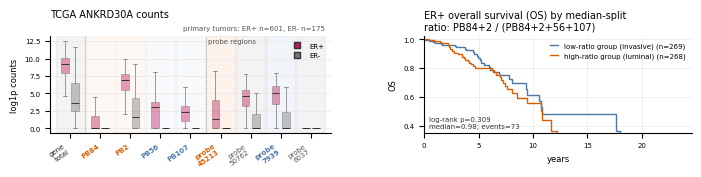

In [16]:
# Preview DU/TCGA panel 3 without writing a PDF.
_tcga_metrics = load_tcga_metrics_cached()
_tcga_clinical = load_tcga_survival_clinical_cached()
_fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 1.75), constrained_layout=False)
_gs = _fig.add_gridspec(1, 2, width_ratios=[1.05, 1.0], left=0.08, right=0.965, top=0.83, bottom=0.28, wspace=0.34)
plot_tcga_count_boxplots(_fig, _gs[0, 0], _tcga_metrics)
plot_tcga_transcript_survival_panel(_fig, _gs[0, 1], _tcga_metrics, _tcga_clinical)
plt.show()
plt.close(_fig)


### Row 4: TCGA TF correlations and T47D TRPS1 PRO-seq

Show ER+ TCGA TF-expression correlations with ANKRD30A usage ratios beside T47D TRPS1-degradation PRO-seq log2 fold changes around PB-defined TSSs. This preview cell does not save a PDF.


In [17]:
# Row 4-right helpers: T47D TRPS1-degradation PRO-seq signal changes.
def plot_trps1_proseq_panel(ax: Any, signal: pd.DataFrame) -> None:
    """Plot cached GSE236172 PRO-seq signal changes around ANKRD30A PB TSSs."""
    if signal.empty:
        raise ValueError("TRPS1 PRO-seq signal cache is empty")
    required = [
        "feature_id",
        "feature_type",
        "plot_order",
        "display_label",
        "event_class",
        "timepoint",
        "timepoint_order",
        "combined_abs_sum",
        "log2fc_combined_abs_sum_vs_0h",
    ]
    require_columns(signal, required, "TRPS1 PRO-seq signal cache")
    plot_df = signal.copy()
    y_floor = -1.0
    y_ceiling = 2.35
    plot_df["combined_abs_sum"] = pd.to_numeric(plot_df["combined_abs_sum"], errors="coerce")
    plot_df["log2fc_combined_abs_sum_vs_0h"] = pd.to_numeric(plot_df["log2fc_combined_abs_sum_vs_0h"], errors="coerce")
    # Several luminal TSS windows have zero summed signal after perturbation;
    # clip only the display coordinate so those floor effects do not dominate
    # the y-axis scale used to inspect the invasive TSS activation curves.
    plot_df["display_log2fc"] = plot_df["log2fc_combined_abs_sum_vs_0h"].clip(lower=y_floor, upper=y_ceiling)
    plot_df["is_zero_signal"] = plot_df["combined_abs_sum"].fillna(0).le(0)
    plot_df["timepoint"] = pd.Categorical(plot_df["timepoint"], categories=["0h", "0.5h", "1h", "2h", "4h", "24h"], ordered=True)
    plot_df = plot_df.sort_values(["plot_order", "timepoint"])
    colors = {"luminal": LUMINAL_ASSOC_COLOR, "invasive": INVASIVE_ASSOC_COLOR, "control": "#333333"}
    label_offsets = {"PB.3828.84": 0.08, "PB.3828.2": -0.10, "PB.3828.56": -0.03, "PB.3828.107": 0.09, "ANKRD30A_gene_body": -0.05}
    for _, sub in plot_df.groupby("feature_id", sort=False):
        feature_id = str(sub["feature_id"].iloc[0])
        event_class = str(sub["event_class"].iloc[0])
        feature_type = str(sub["feature_type"].iloc[0])
        style = TRPS1_PROSEQ_FEATURE_STYLES.get(feature_id, {})
        line_color = colors.get(event_class, "0.5")
        ax.plot(
            sub["timepoint_order"],
            sub["display_log2fc"],
            marker=style.get("marker", "o"),
            markersize=3.1,
            linewidth=1.45 if feature_type == "gene_body" else 1.1,
            linestyle=style.get("linestyle", "-"),
            color=line_color,
            alpha=style.get("alpha", 1.0),
        )
        zero = sub[sub["is_zero_signal"]]
        if not zero.empty:
            ax.scatter(
                zero["timepoint_order"],
                np.full(zero.shape[0], y_floor),
                marker="v",
                s=14,
                facecolors="white",
                edgecolors=line_color,
                linewidths=0.65,
                zorder=4,
            )
        endpoint = sub.sort_values("timepoint_order").iloc[-1]
        label = "gene body" if feature_type == "gene_body" else feature_id.replace("PB.3828.", "PB")
        ax.text(
            float(endpoint["timepoint_order"]) + 0.08,
            float(endpoint["display_log2fc"]) + label_offsets.get(feature_id, 0.0),
            label,
            color=line_color,
            fontsize=4.8,
            va="center",
            ha="left",
            clip_on=False,
        )
    ax.axhline(0, color="0.65", linewidth=0.6)
    ax.text(0.02, 0.04, "zero signal clipped", transform=ax.transAxes, fontsize=4.7, color="0.35", ha="left", va="bottom")
    ax.set_xticks(range(6), ["0h", "0.5h", "1h", "2h", "4h", "24h"])
    ax.set_xlabel("TRPS1 degradation time")
    ax.set_ylabel("log2FC summed PRO-seq vs 0h", labelpad=2)
    ax.set_title("T47D TRPS1-KO PRO-seq (±1Kb TSS, both strands)", loc="left", y=1.2, pad=0)
    ax.set_xlim(-0.2, 5.78)
    ax.set_ylim(y_floor - 0.08, y_ceiling)
    ax.set_yticks([-1, 0, 1, 2], ["≤-1", "0", "+1", "+2"])
    color_handles = [
        Line2D([0], [0], color=LUMINAL_ASSOC_COLOR, linewidth=1.4, label="luminal TSS"),
        Line2D([0], [0], color=INVASIVE_ASSOC_COLOR, linewidth=1.4, label="invasive TSS"),
        Line2D([0], [0], color="#333333", linewidth=1.4, label="gene body"),
        Line2D([0], [0], color="0.35", marker="v", markerfacecolor="white", linestyle="None", markersize=3.0, label="zero signal"),
    ]
    ax.legend(handles=color_handles, frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.03), ncol=4, fontsize=4.8, handlelength=1.35, columnspacing=0.8)
    ax.grid(axis="y", color="#E8E8E8", linewidth=0.45)
    ax.spines[["top", "right"]].set_visible(False)

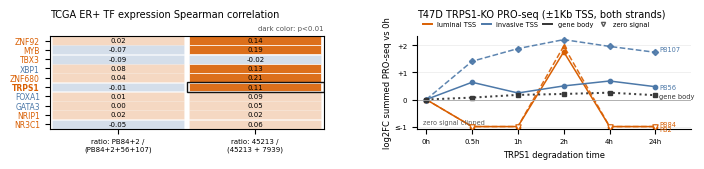

In [18]:
# Preview DU/TCGA panel 4 without writing a PDF.
_tf_inputs = load_tf_priority_inputs()
_tcga_corr = load_tcga_correlations_cached()
_trps1_signal = load_trps1_proseq_cached()
_fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 1.75), constrained_layout=False)
_gs = _fig.add_gridspec(1, 2, width_ratios=[1.0, 1.0], left=0.08, right=0.965, top=0.83, bottom=0.30, wspace=0.34)
plot_tcga_panel(_fig, _gs[0, 0], _tcga_corr, _tf_inputs["focus_tfs"], tf_logfc=_tf_inputs["tf_logfc"])
_ax = _fig.add_subplot(_gs[0, 1])
plot_trps1_proseq_panel(_ax, _trps1_signal)
plt.show()
plt.close(_fig)


### Combined ANKRD30A DU/TCGA figure

Assemble the four-row previewed panels into the final supplementary figure, display it in the notebook, and save the PDF.


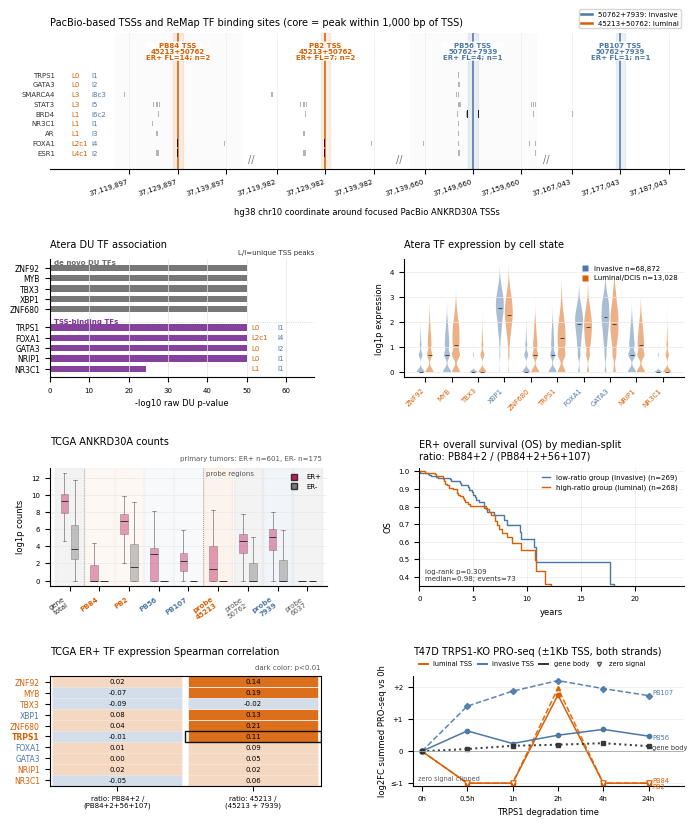

PosixPath('/Users/jysumac/Projects/quadsv-paper/figures/atera_ffpe_human_brca/atera_ankrd30a_du_tcga.pdf')

In [19]:
# Combined DU/TCGA figure: show in notebook and save the PDF.
_tss_inputs = load_tss_binding_inputs()
_tf_inputs = load_tf_priority_inputs()
_tcga_metrics = load_tcga_metrics_cached()
_tcga_corr = load_tcga_correlations_cached()
_tcga_clinical = load_tcga_survival_clinical_cached()
_trps1_signal = load_trps1_proseq_cached()
DU_TCGA_FIGURE_PDF.parent.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(FIGURE_WIDTH_IN, DU_TCGA_FIGURE_HEIGHT_IN), constrained_layout=False)
outer = fig.add_gridspec(
    4,
    1,
    height_ratios=[1.55, 1.35, 1.35, 1.25],
    left=0.075,
    right=0.95,
    top=0.95,
    bottom=0.08,
    hspace=0.75,
)

# Row 1: PB-defined TSS windows and nearby ReMap TF binding support.
ax_tss = fig.add_subplot(outer[0, 0])
plot_pb_tss_hypothesis(
    ax_tss,
    _tss_inputs["hypothesis_tss"],
    _tss_inputs["remap_pb"],
    _tss_inputs["binding_by_class"],
)

# Row 2: Atera DU associations and matching TF expression shifts in spatial cell states.
du_gs = outer[1, 0].subgridspec(1, 2, width_ratios=[1.02, 1.08], wspace=0.33)
plot_ankrd_tf_priority(
    fig,
    du_gs[0, 0],
    _tf_inputs["focus_priority"],
    binding_by_class=_tss_inputs["binding_by_class"],
)
plot_atera_tf_expression_violins(
    fig,
    du_gs[0, 1],
    _tf_inputs["violin_data"],
    _tf_inputs["violin_tfs"],
    tf_logfc=_tf_inputs["tf_logfc"],
    group_counts=_tf_inputs["violin_counts"],
)

# Row 3: TCGA ER+/ER- transcript/probe counts and ER+ transcript-ratio survival.
tcga_gs = outer[2, 0].subgridspec(1, 2, width_ratios=[1.05, 1.0], wspace=0.34)
plot_tcga_count_boxplots(fig, tcga_gs[0, 0], _tcga_metrics)
plot_tcga_transcript_survival_panel(fig, tcga_gs[0, 1], _tcga_metrics, _tcga_clinical)

# Row 4: TCGA ER+ TF-expression correlations and T47D TRPS1-degradation PRO-seq.
validation_gs = outer[3, 0].subgridspec(1, 2, width_ratios=[1.0, 1.0], wspace=0.34)
plot_tcga_panel(fig, validation_gs[0, 0], _tcga_corr, _tf_inputs["focus_tfs"], tf_logfc=_tf_inputs["tf_logfc"])
ax_proseq = fig.add_subplot(validation_gs[0, 1])
plot_trps1_proseq_panel(ax_proseq, _trps1_signal)

fig.savefig(DU_TCGA_FIGURE_PDF)
plt.show()
plt.close(fig)
DU_TCGA_FIGURE_PDF
